# Data preparation

Unzips PADS, builds the master metadata and NPZ files, engineers sensor features and creates the fixed patient-level outer folds used by every model.

Part of the code for *Robust Non-Motor Symptom Modeling for Parkinson's Disease Differential Diagnosis*. See the repository README for the run order.

In [ ]:
# Download PADS v1.0.0 from https://doi.org/10.13026/m0w9-zx22 and upload the zip to /content
!unzip -q /content/pads-parkinsons-disease-smartwatch-dataset-1.0.0.zip -d /content/pads_dataset

## Consolidation and initial EDA

PADS DATA CONSOLIDATION AND INITIAL EDA
Dataset path: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0
Output path : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data

Located files and folders:
Metadata CSV             : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/preprocessed/file_list.csv
Preprocessed movement    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/preprocessed/movement
Preprocessed questionnaire: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/preprocessed/questionnaire
Raw task-wise signals    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/movement/timeseries
Patient JSON folder      : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/patients
Scripts folder           : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/scripts

File inventory:
Metadata participants   

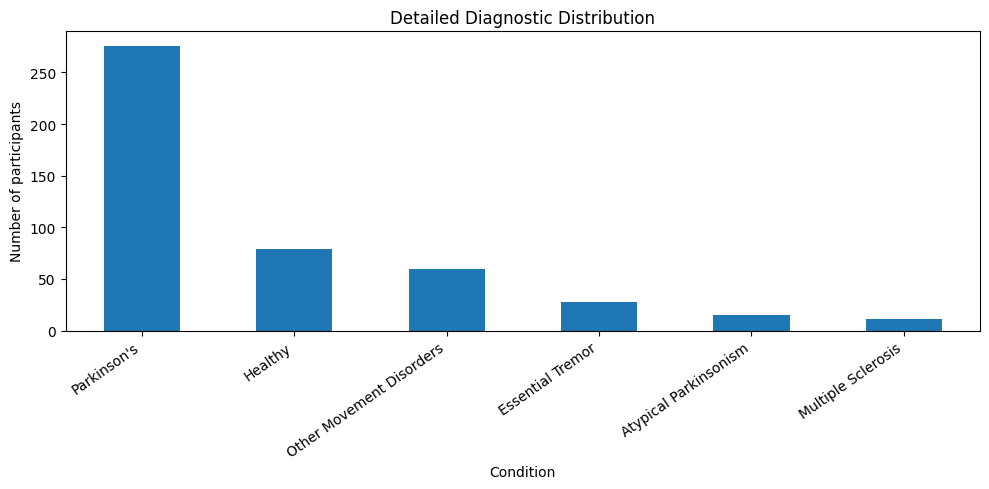

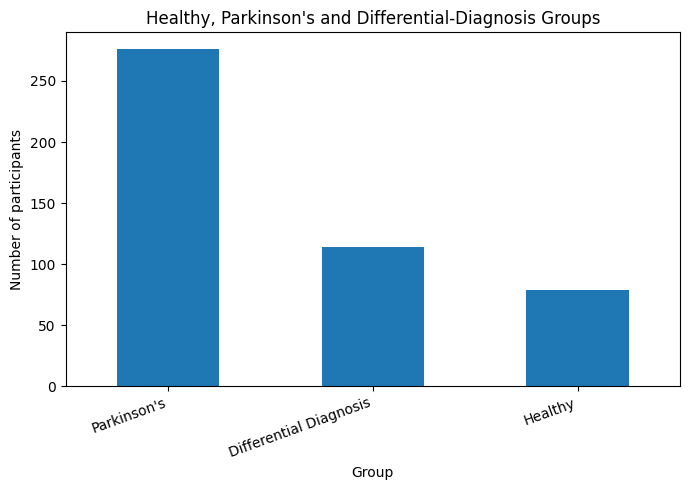

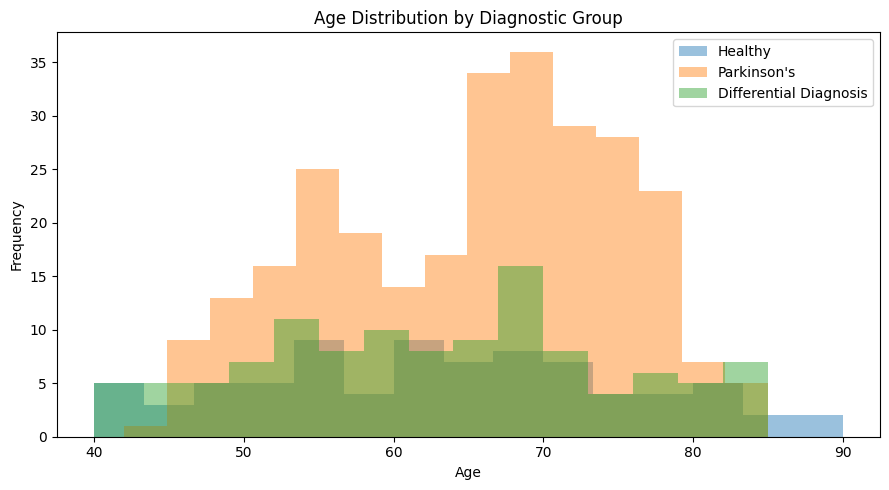

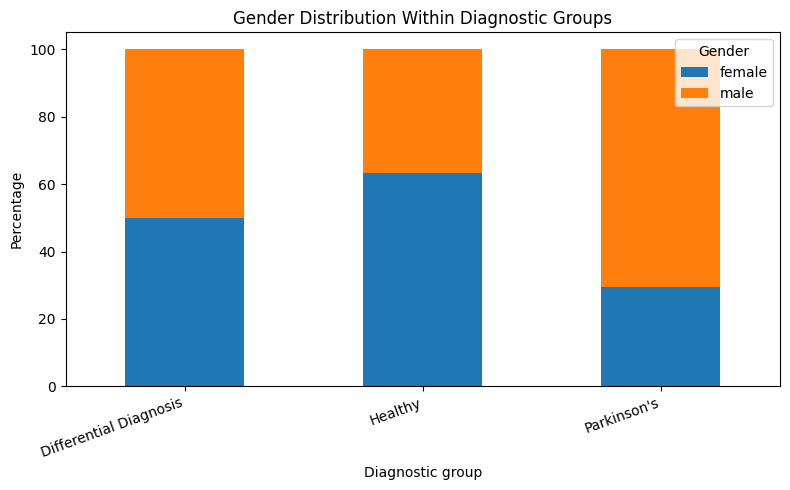

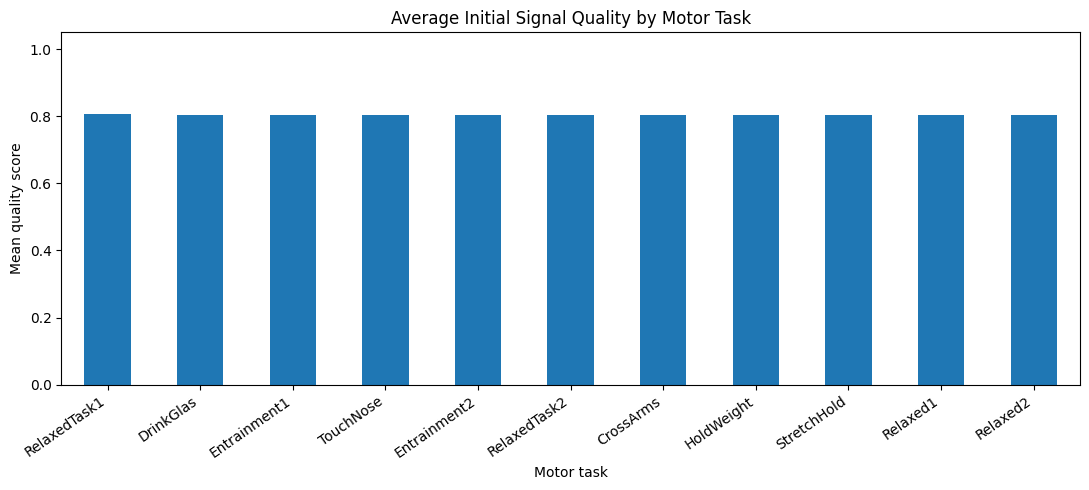

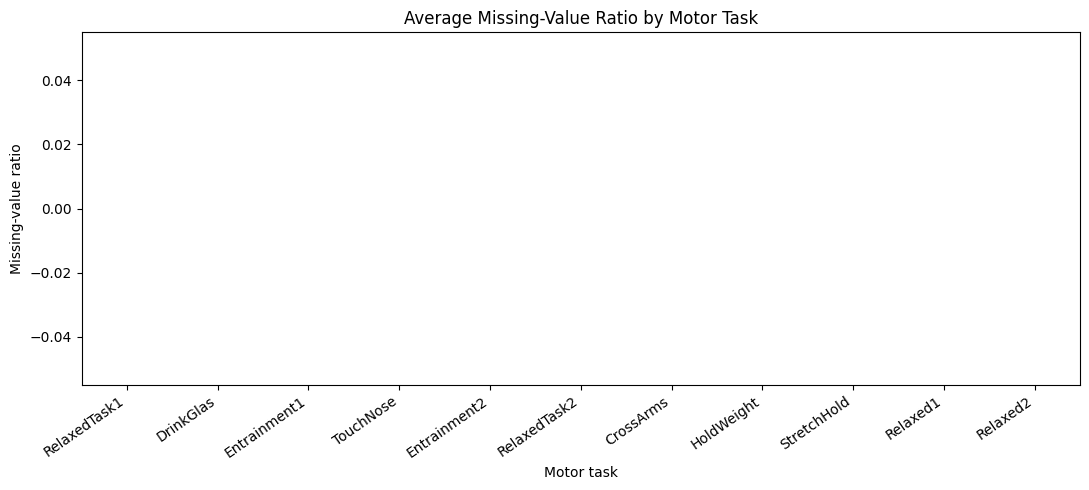

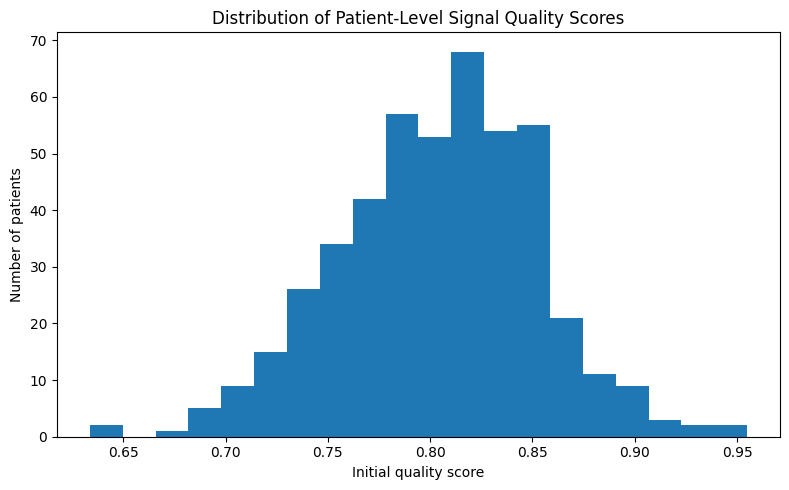

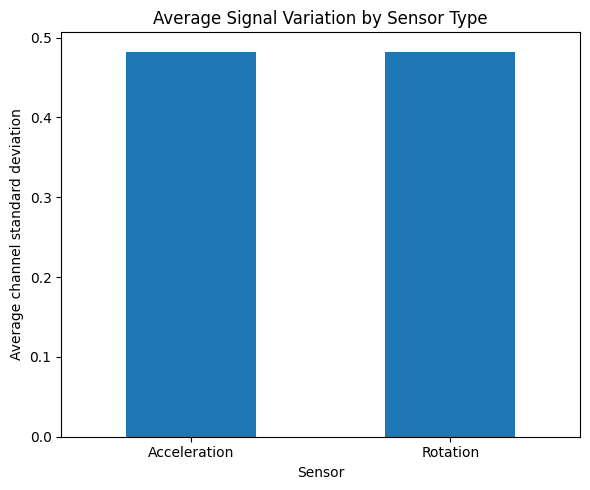

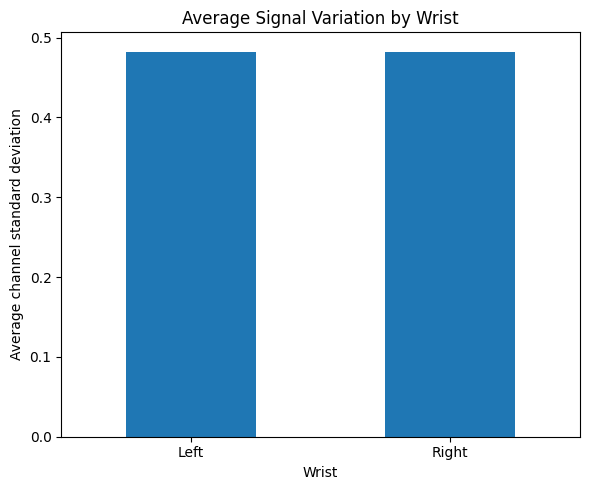


AUTOMATIC PREPROCESSING RECOMMENDATIONS
PADS INITIAL PREPROCESSING RECOMMENDATIONS
Participants successfully loaded: 469
Movement tensor shape: (469, 976, 132)
Questionnaire tensor shape: (469, 30)

1. PRIMARY COHORT
- Primary analysis should use Parkinson's versus Differential Diagnosis.
- Healthy participants should be retained for supplementary PD-versus-Healthy analysis.

2. MISSING VALUES
- No missing values were detected in the consolidated movement tensor.

3. CONSTANT OR LOW-VARIANCE SIGNALS
- Channels with at least one constant patient recording: 0.
- Remove a feature/channel only when it is constant or near-constant in the training fold.
- Do not remove channels using information from the outer test fold.

4. SCALING
- Accelerometer and gyroscope have different units and numerical ranges.
- Fit StandardScaler or robust scaling only on training patients.
- For deep models, normalize per channel using training-fold statistics.

5. FILTERING
- These files are already preprocess

In [13]:
# ================================================================
# PADS DATASET: ONE-CELL CONSOLIDATION + COMPLETE INITIAL EDA
# ================================================================
# OUTPUTS:
# 1. pads_complete_data.npz
#       - All patients' movement data
#       - Questionnaire data
#       - Labels
#       - Patient IDs
#       - Channel/task information
#
# 2. pads_master_metadata.csv
# 3. pads_patient_quality_report.csv
# 4. pads_channel_quality_report.csv
# 5. pads_eda_summary.txt
# 6. figures/*.png
#
# IMPORTANT:
# - This code does NOT train any model.
# - This code prepares and examines the complete dataset.
# - Change BASE_DIR only.
# ================================================================

import os
import re
import json
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ================================================================
# 1. CHANGE ONLY THIS PATH
# ================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

# Google Drive example:
# BASE_DIR = Path(
#     "/content/drive/MyDrive/pads_dataset/"
#     "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
# )

OUTPUT_DIR = BASE_DIR / "project_ready_data"
FIGURE_DIR = OUTPUT_DIR / "figures"
REFERENCE_DIR = OUTPUT_DIR / "reference_files"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REFERENCE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 90)
print("PADS DATA CONSOLIDATION AND INITIAL EDA")
print("=" * 90)
print("Dataset path:", BASE_DIR)
print("Output path :", OUTPUT_DIR)

if not BASE_DIR.exists():
    raise FileNotFoundError(
        f"\nDataset folder not found:\n{BASE_DIR}\n"
        "Please correct BASE_DIR."
    )

# ================================================================
# 2. AUTOMATICALLY LOCATE IMPORTANT FILES AND FOLDERS
# ================================================================

def find_first(root, pattern, required=True):
    matches = list(root.rglob(pattern))

    if not matches:
        if required:
            raise FileNotFoundError(
                f"Could not find '{pattern}' inside:\n{root}"
            )
        return None

    return matches[0]


file_list_path = find_first(BASE_DIR, "file_list.csv")

preprocessed_movement_dir = next(
    (
        path for path in BASE_DIR.rglob("movement")
        if path.is_dir() and path.parent.name == "preprocessed"
    ),
    None
)

preprocessed_questionnaire_dir = next(
    (
        path for path in BASE_DIR.rglob("questionnaire")
        if path.is_dir() and path.parent.name == "preprocessed"
    ),
    None
)

raw_timeseries_dir = next(
    (
        path for path in BASE_DIR.rglob("timeseries")
        if path.is_dir() and path.parent.name == "movement"
    ),
    None
)

patient_json_dir = next(
    (
        path for path in BASE_DIR.rglob("patients")
        if path.is_dir()
    ),
    None
)

scripts_dir = next(
    (
        path for path in BASE_DIR.rglob("scripts")
        if path.is_dir()
    ),
    None
)

license_path = find_first(BASE_DIR, "LICENSE.txt", required=False)
checksums_path = find_first(BASE_DIR, "SHA256SUMS.txt", required=False)

if preprocessed_movement_dir is None:
    raise FileNotFoundError("preprocessed/movement folder was not found.")

if preprocessed_questionnaire_dir is None:
    raise FileNotFoundError(
        "preprocessed/questionnaire folder was not found."
    )

print("\nLocated files and folders:")
print("Metadata CSV             :", file_list_path)
print("Preprocessed movement    :", preprocessed_movement_dir)
print("Preprocessed questionnaire:", preprocessed_questionnaire_dir)
print("Raw task-wise signals    :", raw_timeseries_dir)
print("Patient JSON folder      :", patient_json_dir)
print("Scripts folder           :", scripts_dir)

# Copy important reference files into output folder
reference_items = [
    file_list_path,
    license_path,
    checksums_path,
]

for source in reference_items:
    if source is not None and source.exists():
        shutil.copy2(source, REFERENCE_DIR / source.name)

# Copy scripts folder for future reference
if scripts_dir is not None and scripts_dir.exists():
    copied_scripts_dir = REFERENCE_DIR / "scripts"

    if not copied_scripts_dir.exists():
        shutil.copytree(
            scripts_dir,
            copied_scripts_dir,
            dirs_exist_ok=True,
        )

# ================================================================
# 3. LOAD AND PREPARE METADATA
# ================================================================

metadata = pd.read_csv(file_list_path)

if "id" not in metadata.columns:
    raise ValueError("Metadata does not contain an 'id' column.")

if "condition" not in metadata.columns:
    raise ValueError("Metadata does not contain a 'condition' column.")

metadata["id_numeric"] = pd.to_numeric(
    metadata["id"],
    errors="coerce",
)

metadata["patient_id"] = (
    metadata["id_numeric"]
    .astype("Int64")
    .astype(str)
    .str.zfill(3)
)

metadata["condition_original"] = (
    metadata["condition"]
    .astype(str)
    .str.strip()
)

# ------------------------------------------------
# Create clinically useful grouped diagnosis labels
# ------------------------------------------------

differential_conditions = [
    "Other Movement Disorders",
    "Essential Tremor",
    "Atypical Parkinsonism",
    "Multiple Sclerosis",
]

def create_three_class_label(condition):
    if condition == "Healthy":
        return "Healthy"

    if condition == "Parkinson's":
        return "Parkinson's"

    if condition in differential_conditions:
        return "Differential Diagnosis"

    return "Unknown"


metadata["condition_3class"] = metadata[
    "condition_original"
].apply(create_three_class_label)

# Primary binary project label:
# 1 = Parkinson's disease
# 0 = Differential diagnosis
# NaN = Healthy or unknown

metadata["y_binary"] = np.where(
    metadata["condition_3class"] == "Parkinson's",
    1,
    np.where(
        metadata["condition_3class"] == "Differential Diagnosis",
        0,
        np.nan,
    ),
)

three_class_mapping = {
    "Healthy": 0,
    "Parkinson's": 1,
    "Differential Diagnosis": 2,
}

metadata["y_3class"] = metadata[
    "condition_3class"
].map(three_class_mapping)

# ------------------------------------------------
# Convert numerical demographic fields
# ------------------------------------------------

for column in [
    "age",
    "height",
    "weight",
    "age_at_diagnosis",
]:
    if column in metadata.columns:
        metadata[column] = pd.to_numeric(
            metadata[column],
            errors="coerce",
        )

if {"height", "weight"}.issubset(metadata.columns):
    metadata["bmi"] = (
        metadata["weight"] /
        ((metadata["height"] / 100) ** 2)
    )

    metadata.loc[
        (metadata["height"] <= 0) |
        (metadata["weight"] <= 0) |
        (~np.isfinite(metadata["bmi"])),
        "bmi",
    ] = np.nan

if {"age", "age_at_diagnosis"}.issubset(metadata.columns):
    metadata["disease_duration_proxy"] = (
        metadata["age"] -
        metadata["age_at_diagnosis"]
    )

# ================================================================
# 4. DISCOVER ALL PREPROCESSED FILES
# ================================================================

movement_files = sorted(
    preprocessed_movement_dir.glob("*.bin")
)

questionnaire_files = sorted(
    preprocessed_questionnaire_dir.glob("*.bin")
)

def extract_patient_id(file_path):
    match = re.search(r"(\d{1,3})", file_path.stem)

    if match is None:
        return None

    return str(int(match.group(1))).zfill(3)


movement_file_map = {
    extract_patient_id(path): path
    for path in movement_files
    if extract_patient_id(path) is not None
}

questionnaire_file_map = {
    extract_patient_id(path): path
    for path in questionnaire_files
    if extract_patient_id(path) is not None
}

print("\nFile inventory:")
print("Metadata participants       :", len(metadata))
print("Movement binary files       :", len(movement_file_map))
print("Questionnaire binary files  :", len(questionnaire_file_map))

# ================================================================
# 5. EXPECTED PREPROCESSED MOVEMENT STRUCTURE
# ================================================================

# PADS preprocessed dataset contains:
# 11 task segments × 2 sensors × 2 wrists × 3 axes = 132 channels

TASKS = [
    "Relaxed1",
    "Relaxed2",
    "RelaxedTask1",
    "RelaxedTask2",
    "StretchHold",
    "HoldWeight",
    "DrinkGlas",
    "CrossArms",
    "TouchNose",
    "Entrainment1",
    "Entrainment2",
]

SENSORS = [
    "Acceleration",
    "Rotation",
]

WRISTS = [
    "Left",
    "Right",
]

AXES = [
    "X",
    "Y",
    "Z",
]

CHANNEL_NAMES = [
    f"{task}_{sensor}_{wrist}_{axis}"
    for task in TASKS
    for sensor in SENSORS
    for wrist in WRISTS
    for axis in AXES
]

N_TASKS = len(TASKS)
N_CHANNELS_PER_TASK = (
    len(SENSORS) *
    len(WRISTS) *
    len(AXES)
)
N_CHANNELS = len(CHANNEL_NAMES)

EXPECTED_TIME_POINTS = 976

assert N_TASKS == 11
assert N_CHANNELS_PER_TASK == 12
assert N_CHANNELS == 132

channel_map_rows = []

for channel_index, channel_name in enumerate(CHANNEL_NAMES):
    task_index = channel_index // N_CHANNELS_PER_TASK

    within_task_index = (
        channel_index % N_CHANNELS_PER_TASK
    )

    sensor_index = (
        within_task_index //
        (len(WRISTS) * len(AXES))
    )

    remainder = (
        within_task_index %
        (len(WRISTS) * len(AXES))
    )

    wrist_index = remainder // len(AXES)
    axis_index = remainder % len(AXES)

    channel_map_rows.append({
        "channel_index": channel_index,
        "channel_name": channel_name,
        "task_index": task_index,
        "task": TASKS[task_index],
        "sensor": SENSORS[sensor_index],
        "wrist": WRISTS[wrist_index],
        "axis": AXES[axis_index],
    })

channel_map_df = pd.DataFrame(channel_map_rows)

channel_map_df.to_csv(
    OUTPUT_DIR / "pads_channel_map.csv",
    index=False,
)

print("\nExpected preprocessed movement shape:")
print(
    f"Approximately "
    f"({EXPECTED_TIME_POINTS}, {N_CHANNELS}) "
    f"per patient"
)

# ================================================================
# 6. ROBUST MOVEMENT BINARY LOADER
# ================================================================

def load_movement_file(file_path):
    """
    Tests float64 and float32 interpretations.

    Selects the interpretation that:
    - is divisible by 132 channels;
    - produces a number of time points closest to 976.

    Returns:
        array: shape (time_points, 132)
        loader_info: dictionary
    """

    candidates = []

    for dtype in [np.float64, np.float32]:
        raw = np.fromfile(
            file_path,
            dtype=dtype,
        )

        if raw.size == 0:
            continue

        if raw.size % N_CHANNELS != 0:
            continue

        time_points = raw.size // N_CHANNELS

        candidates.append({
            "dtype": dtype,
            "raw": raw,
            "time_points": int(time_points),
            "distance": abs(
                int(time_points) -
                EXPECTED_TIME_POINTS
            ),
        })

    if not candidates:
        raise ValueError(
            f"{file_path.name} cannot be reshaped "
            f"into {N_CHANNELS} channels."
        )

    candidates = sorted(
        candidates,
        key=lambda item: item["distance"],
    )

    best = candidates[0]

    movement = best["raw"].reshape(
        best["time_points"],
        N_CHANNELS,
    )

    movement = movement.astype(np.float32)

    info = {
        "filename": file_path.name,
        "dtype": np.dtype(best["dtype"]).name,
        "total_values": int(best["raw"].size),
        "time_points": int(best["time_points"]),
        "channels": N_CHANNELS,
    }

    return movement, info


def standardize_time_length(
    movement,
    target_length=EXPECTED_TIME_POINTS,
):
    """
    Makes all patients have the same time dimension.

    Longer signals:
        truncated to target length.

    Shorter signals:
        padded with NaN values.
    """

    current_length = movement.shape[0]

    if current_length == target_length:
        return movement

    if current_length > target_length:
        return movement[:target_length]

    padding_length = target_length - current_length

    padding = np.full(
        (padding_length, movement.shape[1]),
        np.nan,
        dtype=np.float32,
    )

    return np.vstack([
        movement,
        padding,
    ])


# ================================================================
# 7. QUESTIONNAIRE LOADER
# ================================================================

def load_questionnaire_file(
    file_path,
    expected_length=30,
):
    """
    Attempts common dtypes and chooses the one closest
    to 30 questionnaire values.
    """

    candidates = []

    for dtype in [
        np.float64,
        np.float32,
        np.int64,
        np.int32,
    ]:
        raw = np.fromfile(
            file_path,
            dtype=dtype,
        )

        candidates.append({
            "dtype": dtype,
            "raw": raw,
            "distance": abs(
                raw.size - expected_length
            ),
        })

    candidates = sorted(
        candidates,
        key=lambda item: item["distance"],
    )

    best = candidates[0]

    questionnaire = best["raw"].astype(
        np.float32
    )

    if questionnaire.size > expected_length:
        questionnaire = questionnaire[
            :expected_length
        ]

    elif questionnaire.size < expected_length:
        padded = np.full(
            expected_length,
            np.nan,
            dtype=np.float32,
        )

        padded[:questionnaire.size] = (
            questionnaire
        )

        questionnaire = padded

    return questionnaire, np.dtype(
        best["dtype"]
    ).name


# ================================================================
# 8. SIGNAL QUALITY FUNCTIONS
# ================================================================

def calculate_signal_quality(signal):
    """
    Provides simple initial quality indicators.

    This does not declare whether a clinical signal
    is good or bad. It helps identify suspicious files.
    """

    signal = np.asarray(
        signal,
        dtype=float,
    )

    finite_mask = np.isfinite(signal)

    missing_ratio = (
        1.0 - finite_mask.mean()
    )

    finite_values = signal[finite_mask]

    if finite_values.size == 0:
        return {
            "missing_ratio": 1.0,
            "zero_ratio": 1.0,
            "constant_signal": 1,
            "extreme_ratio": 1.0,
            "quality_score": 0.0,
        }

    zero_ratio = np.mean(
        np.isclose(
            finite_values,
            0.0,
            atol=1e-10,
        )
    )

    signal_std = np.std(finite_values)

    constant_signal = int(
        signal_std < 1e-8
    )

    median = np.median(finite_values)

    mad = np.median(
        np.abs(
            finite_values - median
        )
    )

    if mad > 0:
        robust_z = (
            0.6745 *
            (finite_values - median) /
            mad
        )

        extreme_ratio = np.mean(
            np.abs(robust_z) > 10
        )

    else:
        extreme_ratio = 0.0

    # Initial heuristic quality score
    penalty = (
        missing_ratio +
        (0.25 * zero_ratio) +
        (2.0 * extreme_ratio) +
        (0.5 * constant_signal)
    )

    quality_score = max(
        0.0,
        1.0 - min(1.0, penalty),
    )

    return {
        "missing_ratio": float(
            missing_ratio
        ),
        "zero_ratio": float(
            zero_ratio
        ),
        "constant_signal": int(
            constant_signal
        ),
        "extreme_ratio": float(
            extreme_ratio
        ),
        "quality_score": float(
            quality_score
        ),
    }


def get_task_channel_slice(task_index):
    start = (
        task_index *
        N_CHANNELS_PER_TASK
    )

    end = (
        start +
        N_CHANNELS_PER_TASK
    )

    return slice(start, end)


# ================================================================
# 9. LOAD ALL PATIENTS INTO ONE DATA OBJECT
# ================================================================

movement_arrays = []
questionnaire_arrays = []
processed_patient_ids = []

patient_quality_rows = []
channel_quality_rows = []
task_quality_rows = []
loader_rows = []

print("\n" + "=" * 90)
print("LOADING ALL PATIENT FILES")
print("=" * 90)

for metadata_index, row in metadata.iterrows():

    patient_id = row["patient_id"]

    movement_path = movement_file_map.get(
        patient_id
    )

    if movement_path is None:
        print(
            f"Warning: no movement file for "
            f"patient {patient_id}"
        )
        continue

    try:
        movement, loader_info = (
            load_movement_file(
                movement_path
            )
        )

    except Exception as error:
        print(
            f"Could not load patient "
            f"{patient_id}: {error}"
        )
        continue

    original_time_points = (
        movement.shape[0]
    )

    movement = standardize_time_length(
        movement
    )

    loader_info["patient_id"] = (
        patient_id
    )

    loader_info[
        "standardized_time_points"
    ] = movement.shape[0]

    loader_rows.append(loader_info)

    # --------------------------------------------
    # Questionnaire
    # --------------------------------------------

    questionnaire_path = (
        questionnaire_file_map.get(
            patient_id
        )
    )

    if questionnaire_path is not None:
        questionnaire, questionnaire_dtype = (
            load_questionnaire_file(
                questionnaire_path
            )
        )

    else:
        questionnaire = np.full(
            30,
            np.nan,
            dtype=np.float32,
        )

        questionnaire_dtype = "missing"

    # --------------------------------------------
    # Overall patient quality
    # --------------------------------------------

    patient_quality = (
        calculate_signal_quality(
            movement.flatten()
        )
    )

    patient_quality_rows.append({
        "patient_id": patient_id,
        "movement_filename": (
            movement_path.name
        ),
        "original_time_points": (
            original_time_points
        ),
        "standardized_time_points": (
            movement.shape[0]
        ),
        "questionnaire_dtype": (
            questionnaire_dtype
        ),
        **patient_quality,
    })

    # --------------------------------------------
    # Per-channel quality
    # --------------------------------------------

    for channel_index in range(
        N_CHANNELS
    ):
        signal = movement[
            :,
            channel_index,
        ]

        quality = calculate_signal_quality(
            signal
        )

        channel_information = (
            channel_map_df.iloc[
                channel_index
            ]
        )

        channel_quality_rows.append({
            "patient_id": patient_id,
            "channel_index": (
                channel_index
            ),
            "channel_name": (
                channel_information[
                    "channel_name"
                ]
            ),
            "task": (
                channel_information[
                    "task"
                ]
            ),
            "sensor": (
                channel_information[
                    "sensor"
                ]
            ),
            "wrist": (
                channel_information[
                    "wrist"
                ]
            ),
            "axis": (
                channel_information[
                    "axis"
                ]
            ),
            "mean": float(
                np.nanmean(signal)
            ),
            "std": float(
                np.nanstd(signal)
            ),
            "minimum": float(
                np.nanmin(signal)
            ),
            "maximum": float(
                np.nanmax(signal)
            ),
            **quality,
        })

    # --------------------------------------------
    # Per-task quality
    # --------------------------------------------

    for task_index, task_name in enumerate(
        TASKS
    ):
        task_slice = get_task_channel_slice(
            task_index
        )

        task_data = movement[
            :,
            task_slice,
        ]

        task_quality = (
            calculate_signal_quality(
                task_data.flatten()
            )
        )

        task_quality_rows.append({
            "patient_id": patient_id,
            "task_index": task_index,
            "task": task_name,
            **task_quality,
        })

    movement_arrays.append(
        movement.astype(np.float32)
    )

    questionnaire_arrays.append(
        questionnaire.astype(np.float32)
    )

    processed_patient_ids.append(
        patient_id
    )

    if (
        len(processed_patient_ids) %
        50 == 0
    ):
        print(
            f"Processed "
            f"{len(processed_patient_ids)} "
            f"patients..."
        )

if len(processed_patient_ids) == 0:
    raise RuntimeError(
        "No patient files were successfully loaded."
    )

print(
    f"\nSuccessfully loaded "
    f"{len(processed_patient_ids)} patients."
)

# ================================================================
# 10. CREATE ONE CONSOLIDATED DATASET
# ================================================================

X_movement = np.stack(
    movement_arrays
).astype(np.float32)

X_questionnaire = np.stack(
    questionnaire_arrays
).astype(np.float32)

processed_metadata = (
    metadata
    .set_index("patient_id")
    .loc[processed_patient_ids]
    .reset_index()
)

y_binary = (
    processed_metadata["y_binary"]
    .to_numpy(dtype=np.float32)
)

y_3class = (
    processed_metadata["y_3class"]
    .to_numpy(dtype=np.float32)
)

condition_original = (
    processed_metadata[
        "condition_original"
    ]
    .astype(str)
    .to_numpy()
)

condition_3class = (
    processed_metadata[
        "condition_3class"
    ]
    .astype(str)
    .to_numpy()
)

# Save all important numerical data in one file
complete_npz_path = (
    OUTPUT_DIR /
    "pads_complete_data.npz"
)

np.savez_compressed(
    complete_npz_path,

    # Main inputs
    X_movement=X_movement,
    X_questionnaire=X_questionnaire,

    # Labels
    y_binary=y_binary,
    y_3class=y_3class,

    # IDs and diagnostic text
    patient_ids=np.array(
        processed_patient_ids
    ),
    condition_original=(
        condition_original
    ),
    condition_3class=(
        condition_3class
    ),

    # Structural information
    task_names=np.array(TASKS),
    sensor_names=np.array(SENSORS),
    wrist_names=np.array(WRISTS),
    axis_names=np.array(AXES),
    channel_names=np.array(
        CHANNEL_NAMES
    ),

    # Shape information
    sampling_rate=np.array([100]),
    expected_time_points=np.array(
        [EXPECTED_TIME_POINTS]
    ),
    number_of_channels=np.array(
        [N_CHANNELS]
    ),
)

# Save metadata
metadata_output_path = (
    OUTPUT_DIR /
    "pads_master_metadata.csv"
)

processed_metadata.to_csv(
    metadata_output_path,
    index=False,
)

# Save quality reports
patient_quality_df = pd.DataFrame(
    patient_quality_rows
)

channel_quality_df = pd.DataFrame(
    channel_quality_rows
)

task_quality_df = pd.DataFrame(
    task_quality_rows
)

loader_df = pd.DataFrame(
    loader_rows
)

patient_quality_df.to_csv(
    OUTPUT_DIR /
    "pads_patient_quality_report.csv",
    index=False,
)

channel_quality_df.to_csv(
    OUTPUT_DIR /
    "pads_channel_quality_report.csv",
    index=False,
)

task_quality_df.to_csv(
    OUTPUT_DIR /
    "pads_task_quality_report.csv",
    index=False,
)

loader_df.to_csv(
    OUTPUT_DIR /
    "pads_binary_loader_report.csv",
    index=False,
)

# ================================================================
# 11. COMPLETE INITIAL EDA
# ================================================================

print("\n" + "=" * 90)
print("EDA RESULTS")
print("=" * 90)

print("\nMovement tensor shape:")
print(
    "Patients × time points × channels =",
    X_movement.shape,
)

print("\nQuestionnaire tensor shape:")
print(X_questionnaire.shape)

print("\nDetailed diagnostic distribution:")
print(
    processed_metadata[
        "condition_original"
    ].value_counts()
)

print("\nThree-class distribution:")
print(
    processed_metadata[
        "condition_3class"
    ].value_counts()
)

print("\nPrimary project cohort:")
print(
    processed_metadata.loc[
        processed_metadata[
            "y_binary"
        ].notna(),
        "condition_3class",
    ].value_counts()
)

print("\nMovement loader dtypes:")
print(
    loader_df["dtype"]
    .value_counts()
)

print("\nOriginal time-point counts:")
print(
    loader_df["time_points"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------
# Missing values
# ------------------------------------------------

total_values = X_movement.size

total_missing = np.isnan(
    X_movement
).sum()

missing_percent = (
    total_missing /
    total_values *
    100
)

total_infinite = np.isinf(
    X_movement
).sum()

print("\nOverall signal missing values:")
print("Missing count   :", total_missing)
print(
    "Missing percent :",
    round(missing_percent, 5),
    "%",
)
print("Infinite values :", total_infinite)

print("\nOverall signal statistics:")
print(
    "Minimum:",
    float(np.nanmin(X_movement)),
)
print(
    "Maximum:",
    float(np.nanmax(X_movement)),
)
print(
    "Mean:",
    float(np.nanmean(X_movement)),
)
print(
    "Standard deviation:",
    float(np.nanstd(X_movement)),
)

# ------------------------------------------------
# Metadata missing values
# ------------------------------------------------

metadata_missing = (
    processed_metadata
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
    .to_frame(
        "missing_count"
    )
)

metadata_missing[
    "missing_percent"
] = (
    metadata_missing[
        "missing_count"
    ] /
    len(processed_metadata) *
    100
)

metadata_missing.to_csv(
    OUTPUT_DIR /
    "pads_metadata_missing_report.csv"
)

print("\nTop metadata fields with missing values:")
print(
    metadata_missing.head(15)
)

# ------------------------------------------------
# Channel-level EDA summary
# ------------------------------------------------

channel_summary = (
    channel_quality_df
    .groupby([
        "channel_index",
        "channel_name",
        "task",
        "sensor",
        "wrist",
        "axis",
    ])
    .agg(
        participants=(
            "patient_id",
            "nunique",
        ),
        mean_signal=(
            "mean",
            "mean",
        ),
        average_std=(
            "std",
            "mean",
        ),
        average_missing_ratio=(
            "missing_ratio",
            "mean",
        ),
        average_zero_ratio=(
            "zero_ratio",
            "mean",
        ),
        constant_patient_count=(
            "constant_signal",
            "sum",
        ),
        average_extreme_ratio=(
            "extreme_ratio",
            "mean",
        ),
        average_quality_score=(
            "quality_score",
            "mean",
        ),
    )
    .reset_index()
)

channel_summary.to_csv(
    OUTPUT_DIR /
    "pads_channel_eda_summary.csv",
    index=False,
)

# ------------------------------------------------
# Task-level EDA summary
# ------------------------------------------------

task_summary = (
    task_quality_df
    .groupby("task")
    .agg(
        participants=(
            "patient_id",
            "nunique",
        ),
        mean_quality=(
            "quality_score",
            "mean",
        ),
        std_quality=(
            "quality_score",
            "std",
        ),
        minimum_quality=(
            "quality_score",
            "min",
        ),
        average_missing_ratio=(
            "missing_ratio",
            "mean",
        ),
        average_zero_ratio=(
            "zero_ratio",
            "mean",
        ),
        average_extreme_ratio=(
            "extreme_ratio",
            "mean",
        ),
        constant_task_count=(
            "constant_signal",
            "sum",
        ),
    )
    .sort_values(
        "mean_quality",
        ascending=False,
    )
)

task_summary.to_csv(
    OUTPUT_DIR /
    "pads_task_eda_summary.csv"
)

print("\nTask-level signal quality summary:")
print(task_summary)

# ================================================================
# 12. EDA FIGURES
# ================================================================

def save_plot(filename):
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


# Figure 1: Detailed diagnosis distribution
plt.figure(figsize=(10, 5))

processed_metadata[
    "condition_original"
].value_counts().plot(
    kind="bar"
)

plt.title(
    "Detailed Diagnostic Distribution"
)
plt.xlabel("Condition")
plt.ylabel("Number of participants")
plt.xticks(
    rotation=35,
    ha="right",
)

save_plot(
    "01_detailed_condition_distribution.png"
)


# Figure 2: Primary groups
plt.figure(figsize=(7, 5))

processed_metadata[
    "condition_3class"
].value_counts().plot(
    kind="bar"
)

plt.title(
    "Healthy, Parkinson's and "
    "Differential-Diagnosis Groups"
)
plt.xlabel("Group")
plt.ylabel("Number of participants")
plt.xticks(
    rotation=20,
    ha="right",
)

save_plot(
    "02_three_class_distribution.png"
)


# Figure 3: Age by group
if "age" in processed_metadata.columns:

    plt.figure(figsize=(9, 5))

    for group_name in [
        "Healthy",
        "Parkinson's",
        "Differential Diagnosis",
    ]:
        values = processed_metadata.loc[
            processed_metadata[
                "condition_3class"
            ] == group_name,
            "age",
        ].dropna()

        if len(values) > 0:
            plt.hist(
                values,
                bins=15,
                alpha=0.45,
                label=group_name,
            )

    plt.title(
        "Age Distribution by "
        "Diagnostic Group"
    )
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.legend()

    save_plot(
        "03_age_distribution.png"
    )


# Figure 4: Gender distribution
if "gender" in processed_metadata.columns:

    gender_table = pd.crosstab(
        processed_metadata[
            "condition_3class"
        ],
        processed_metadata["gender"],
        normalize="index",
    ) * 100

    plt.figure(figsize=(8, 5))

    gender_table.plot(
        kind="bar",
        stacked=True,
        ax=plt.gca(),
    )

    plt.title(
        "Gender Distribution "
        "Within Diagnostic Groups"
    )
    plt.xlabel("Diagnostic group")
    plt.ylabel("Percentage")
    plt.xticks(
        rotation=20,
        ha="right",
    )
    plt.legend(title="Gender")

    save_plot(
        "04_gender_distribution.png"
    )


# Figure 5: Mean signal quality by task
plt.figure(figsize=(11, 5))

task_summary[
    "mean_quality"
].sort_values(
    ascending=False
).plot(
    kind="bar"
)

plt.title(
    "Average Initial Signal "
    "Quality by Motor Task"
)
plt.xlabel("Motor task")
plt.ylabel("Mean quality score")
plt.ylim(0, 1.05)
plt.xticks(
    rotation=35,
    ha="right",
)

save_plot(
    "05_task_quality.png"
)


# Figure 6: Missing signal ratio by task
plt.figure(figsize=(11, 5))

task_summary[
    "average_missing_ratio"
].sort_values(
    ascending=False
).plot(
    kind="bar"
)

plt.title(
    "Average Missing-Value Ratio "
    "by Motor Task"
)
plt.xlabel("Motor task")
plt.ylabel("Missing-value ratio")
plt.xticks(
    rotation=35,
    ha="right",
)

save_plot(
    "06_task_missing_ratio.png"
)


# Figure 7: Overall quality distribution
plt.figure(figsize=(8, 5))

plt.hist(
    patient_quality_df[
        "quality_score"
    ],
    bins=20,
)

plt.title(
    "Distribution of Patient-Level "
    "Signal Quality Scores"
)
plt.xlabel("Initial quality score")
plt.ylabel("Number of patients")

save_plot(
    "07_patient_quality_distribution.png"
)


# Figure 8: Average variation by sensor
sensor_variation = (
    channel_summary
    .groupby("sensor")[
        "average_std"
    ]
    .mean()
)

plt.figure(figsize=(6, 5))

sensor_variation.plot(
    kind="bar"
)

plt.title(
    "Average Signal Variation "
    "by Sensor Type"
)
plt.xlabel("Sensor")
plt.ylabel(
    "Average channel standard deviation"
)
plt.xticks(
    rotation=0
)

save_plot(
    "08_sensor_variation.png"
)


# Figure 9: Average variation by wrist
wrist_variation = (
    channel_summary
    .groupby("wrist")[
        "average_std"
    ]
    .mean()
)

plt.figure(figsize=(6, 5))

wrist_variation.plot(
    kind="bar"
)

plt.title(
    "Average Signal Variation "
    "by Wrist"
)
plt.xlabel("Wrist")
plt.ylabel(
    "Average channel standard deviation"
)
plt.xticks(
    rotation=0
)

save_plot(
    "09_wrist_variation.png"
)


# ================================================================
# 13. AUTOMATIC PREPROCESSING RECOMMENDATIONS
# ================================================================

recommendations = []

recommendations.append(
    "PADS INITIAL PREPROCESSING RECOMMENDATIONS"
)

recommendations.append("=" * 80)

recommendations.append(
    f"Participants successfully loaded: "
    f"{len(processed_patient_ids)}"
)

recommendations.append(
    f"Movement tensor shape: "
    f"{X_movement.shape}"
)

recommendations.append(
    f"Questionnaire tensor shape: "
    f"{X_questionnaire.shape}"
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: labels
# ------------------------------------------------

recommendations.append(
    "1. PRIMARY COHORT"
)

recommendations.append(
    "- Primary analysis should use Parkinson's "
    "versus Differential Diagnosis."
)

recommendations.append(
    "- Healthy participants should be retained "
    "for supplementary PD-versus-Healthy analysis."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: missing values
# ------------------------------------------------

recommendations.append(
    "2. MISSING VALUES"
)

if missing_percent == 0:
    recommendations.append(
        "- No missing values were detected in "
        "the consolidated movement tensor."
    )

elif missing_percent < 1:
    recommendations.append(
        f"- Movement missingness is low "
        f"({missing_percent:.4f}%)."
    )

    recommendations.append(
        "- Use training-fold median imputation "
        "or masking; do not drop many patients."
    )

else:
    recommendations.append(
        f"- Movement missingness is "
        f"{missing_percent:.4f}%."
    )

    recommendations.append(
        "- Use an explicit availability mask and "
        "quality-aware missing-signal handling."
    )

recommendations.append("")

# ------------------------------------------------
# Recommendation: constant/zero channels
# ------------------------------------------------

constant_channel_count = int(
    (
        channel_summary[
            "constant_patient_count"
        ] > 0
    ).sum()
)

recommendations.append(
    "3. CONSTANT OR LOW-VARIANCE SIGNALS"
)

recommendations.append(
    f"- Channels with at least one constant "
    f"patient recording: "
    f"{constant_channel_count}."
)

recommendations.append(
    "- Remove a feature/channel only when it is "
    "constant or near-constant in the training fold."
)

recommendations.append(
    "- Do not remove channels using information "
    "from the outer test fold."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: scaling
# ------------------------------------------------

recommendations.append(
    "4. SCALING"
)

recommendations.append(
    "- Accelerometer and gyroscope have different "
    "units and numerical ranges."
)

recommendations.append(
    "- Fit StandardScaler or robust scaling only "
    "on training patients."
)

recommendations.append(
    "- For deep models, normalize per channel "
    "using training-fold statistics."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: filtering
# ------------------------------------------------

recommendations.append(
    "5. FILTERING"
)

recommendations.append(
    "- These files are already preprocessed."
)

recommendations.append(
    "- Do not apply another filter automatically "
    "until the official preprocessing script is "
    "fully inspected."
)

recommendations.append(
    "- Raw timeseries should be used later for "
    "custom filtering, noise and robustness studies."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: class balance
# ------------------------------------------------

primary_counts = (
    processed_metadata.loc[
        processed_metadata[
            "y_binary"
        ].notna(),
        "condition_3class",
    ]
    .value_counts()
)

recommendations.append(
    "6. CLASS IMBALANCE"
)

recommendations.append(
    f"- Primary cohort distribution:\n"
    f"{primary_counts.to_string()}"
)

recommendations.append(
    "- Use stratified patient-level folds."
)

recommendations.append(
    "- Use class weights or weighted loss inside "
    "training only."
)

recommendations.append(
    "- Report balanced accuracy, macro-F1, "
    "PR-AUC, sensitivity and specificity."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: splitting
# ------------------------------------------------

recommendations.append(
    "7. TRAIN/TEST SPLITTING"
)

recommendations.append(
    "- Split at participant level."
)

recommendations.append(
    "- Never place signal segments from one "
    "participant in both training and testing."
)

recommendations.append(
    "- Recommended: nested stratified "
    "five-fold patient-level cross-validation."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: task quality
# ------------------------------------------------

lowest_quality_tasks = (
    task_summary
    .sort_values(
        "mean_quality"
    )
    .head(3)
    .index
    .tolist()
)

recommendations.append(
    "8. TASK QUALITY"
)

recommendations.append(
    "- Lowest initial quality tasks from this EDA: "
    + ", ".join(lowest_quality_tasks)
)

recommendations.append(
    "- Do not automatically remove these tasks."
)

recommendations.append(
    "- Test quality weighting versus no quality "
    "weighting inside cross-validation."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: questionnaire
# ------------------------------------------------

questionnaire_missing_percent = (
    np.isnan(X_questionnaire).mean() *
    100
)

recommendations.append(
    "9. QUESTIONNAIRE"
)

recommendations.append(
    f"- Questionnaire missingness: "
    f"{questionnaire_missing_percent:.4f}%."
)

recommendations.append(
    "- Keep questionnaire data as an optional "
    "multimodal experiment."
)

recommendations.append(
    "- Main project should first establish "
    "smartwatch-signal-only performance."
)

recommendations.append("")

# ------------------------------------------------
# Recommendation: next step
# ------------------------------------------------

recommendations.append(
    "10. NEXT MODELLING STEP"
)

recommendations.append(
    "- First train Logistic Regression, SVM, "
    "Random Forest and XGBoost using engineered "
    "task-level features."
)

recommendations.append(
    "- Then train a simple 1D-CNN baseline on "
    "the consolidated movement tensor."
)

recommendations.append(
    "- Proposed model should use task-wise "
    "encoding, bilateral asymmetry, task-quality "
    "weighting, adaptive task selection and "
    "calibrated referral."
)

recommendations_text = "\n".join(
    recommendations
)

summary_path = (
    OUTPUT_DIR /
    "pads_eda_summary_and_recommendations.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8",
) as file:
    file.write(
        recommendations_text
    )

print("\n" + "=" * 90)
print("AUTOMATIC PREPROCESSING RECOMMENDATIONS")
print("=" * 90)
print(recommendations_text)

# ================================================================
# 14. FINAL OUTPUT REPORT
# ================================================================

print("\n" + "=" * 90)
print("DATA CONSOLIDATION AND EDA COMPLETE")
print("=" * 90)

print("\nMain modelling file:")
print(complete_npz_path)

print("\nMetadata file:")
print(metadata_output_path)

print("\nImportant reports:")
print(
    OUTPUT_DIR /
    "pads_patient_quality_report.csv"
)
print(
    OUTPUT_DIR /
    "pads_channel_quality_report.csv"
)
print(
    OUTPUT_DIR /
    "pads_task_quality_report.csv"
)
print(
    OUTPUT_DIR /
    "pads_channel_eda_summary.csv"
)
print(
    OUTPUT_DIR /
    "pads_task_eda_summary.csv"
)
print(summary_path)

print("\nMain arrays saved:")
print(
    "X_movement      :",
    X_movement.shape,
)
print(
    "X_questionnaire :",
    X_questionnaire.shape,
)
print(
    "y_binary        :",
    y_binary.shape,
)
print(
    "y_3class        :",
    y_3class.shape,
)

print("\nHow to load the consolidated data later:")

print(
    f"""
data = np.load(
    r"{complete_npz_path}",
    allow_pickle=True
)

X = data["X_movement"]
questionnaire = data["X_questionnaire"]
y = data["y_binary"]
patient_ids = data["patient_ids"]
channel_names = data["channel_names"]

# Primary PD-vs-DD cohort
mask = np.isfinite(y)

X_pd_dd = X[mask]
y_pd_dd = y[mask].astype(int)
ids_pd_dd = patient_ids[mask]

print(X_pd_dd.shape)
print(y_pd_dd.shape)
"""
)

print("\n✅ ALL IMPORTANT DATA IS NOW STORED TOGETHER.")

## Task-wise data and feature engineering

PADS TASK-WISE PREPARATION, FEATURE ENGINEERING AND ADVANCED EDA
Input NPZ : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/pads_complete_data.npz
Metadata  : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/pads_master_metadata.csv
Outputs   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering

Loaded complete movement shape: (469, 976, 132)
Loaded questionnaire shape    : (469, 30)
Sampling rate                 : 100 Hz
Number of tasks               : 11
Number of channels            : 132

Primary cohort:
Patients: 390
PD patients: 276
DD patients: 114
Movement shape: (390, 976, 132)

Channel structure validated:
11 tasks × 2 sensors × 2 wrists × 3 axes = 132 channels

Task-wise shape: (390, 11, 976, 12)
Task-wise reshape successfully verified.

Saved task-wise data:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/proje

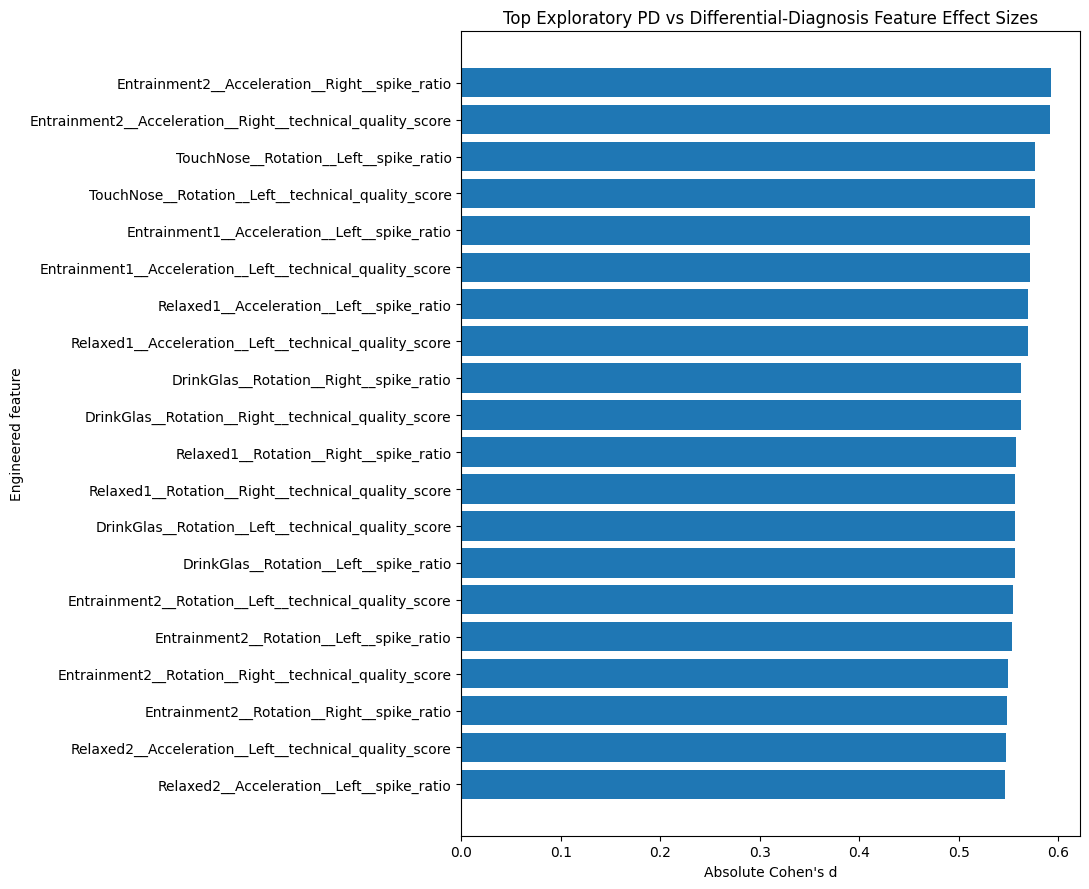

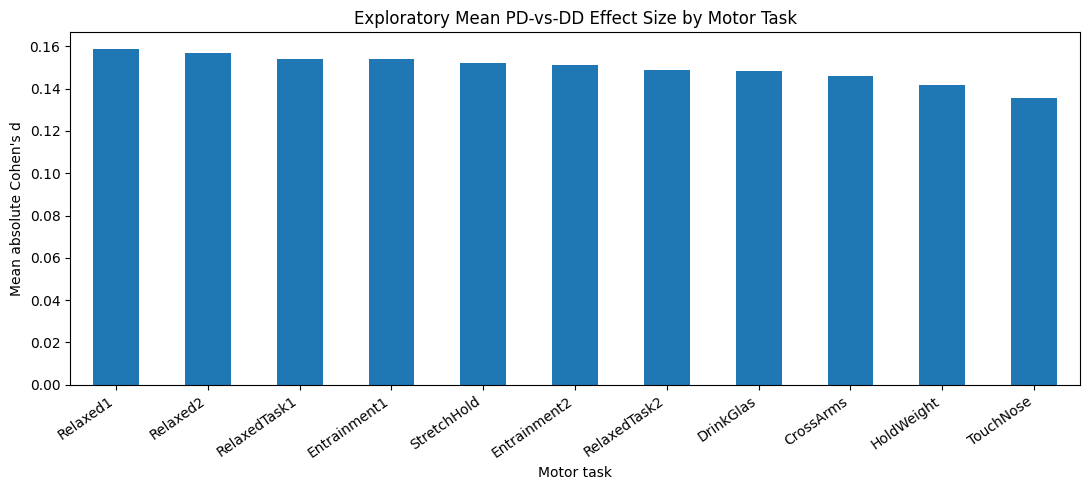

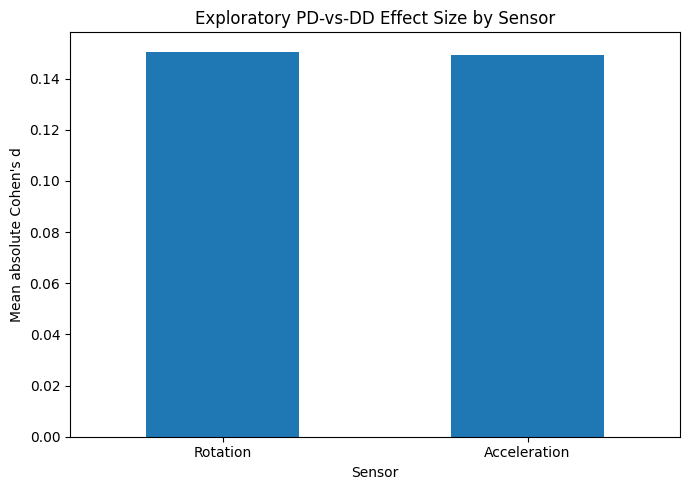

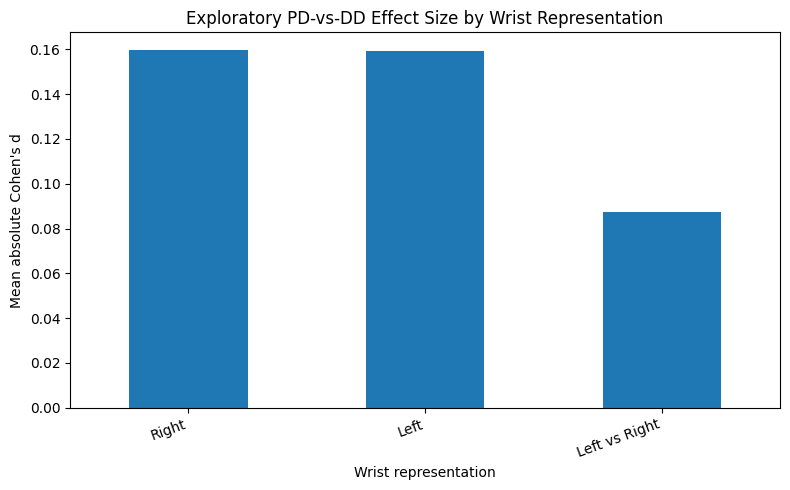

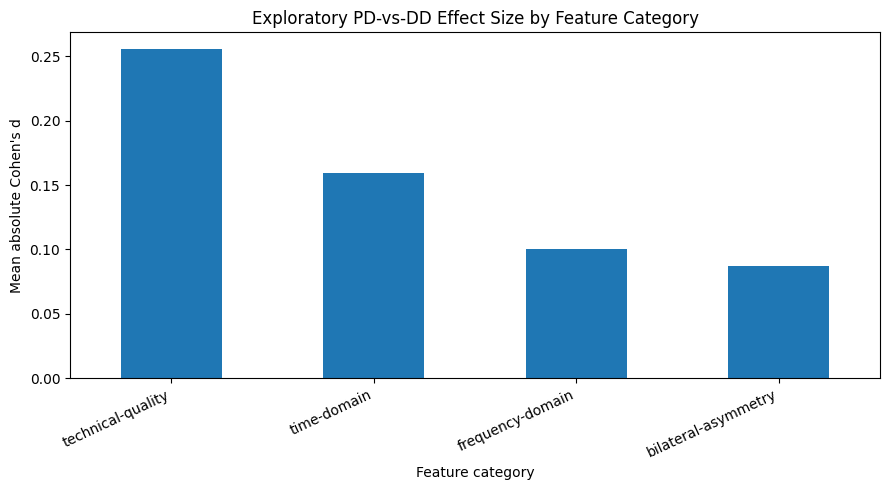

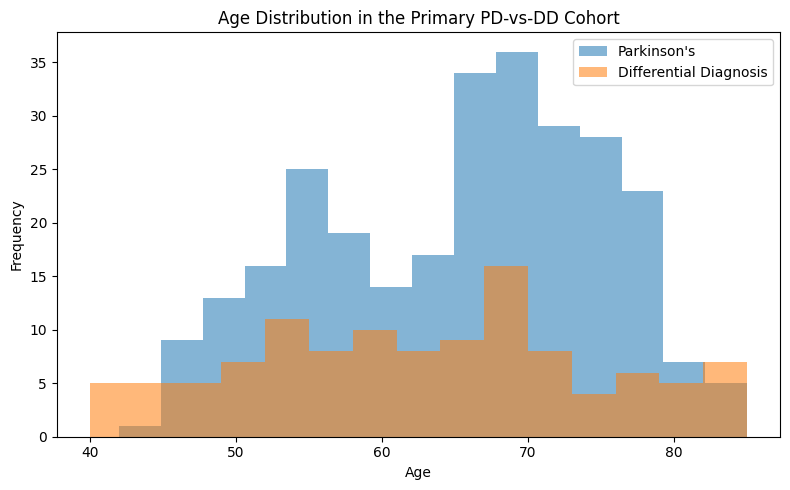

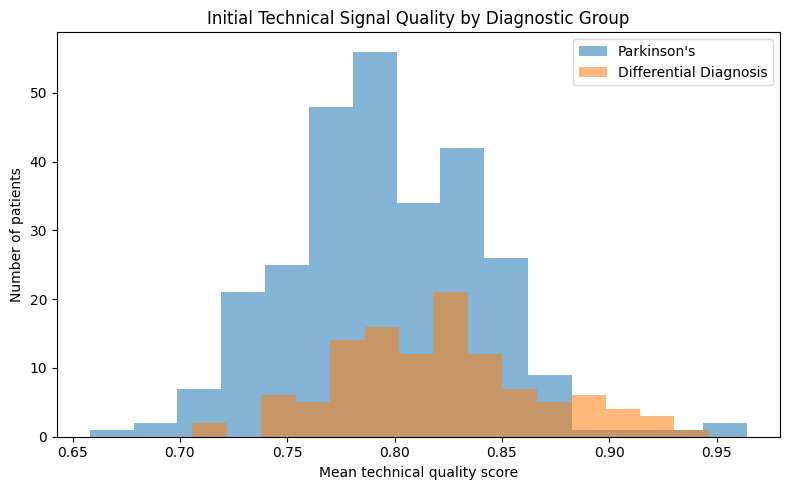


NEXT STEP COMPLETE

Generated primary model files:

1. Proposed/deep-model task-wise data:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_pd_dd_taskwise.npz

2. Baseline engineered-feature table:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv

3. Feature dictionary:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_feature_dictionary.csv

4. Exploratory effect sizes:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_advanced_eda_effect_sizes.csv

5. Summary report:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/feature_engineering_advanced_eda_summary.txt

Final shapes:
Task-wise tensor:
(390, 11, 976, 12)

Engineered feature table:
(390,

In [14]:
# =====================================================================
# PADS NEXT STEP — TASK-WISE DATA + FEATURE ENGINEERING + ADVANCED EDA
# =====================================================================
# This single cell will:
#
# 1. Load pads_complete_data.npz
# 2. Select primary PD-vs-Differential-Diagnosis cohort
# 3. Reshape data:
#       (390, 976, 132) -> (390, 11, 976, 12)
# 4. Extract:
#       - time-domain features
#       - frequency-domain features
#       - quality features
#       - explicit bilateral asymmetry features
# 5. Merge useful metadata
# 6. Generate advanced EDA
# 7. Save:
#       - pads_pd_dd_taskwise.npz
#       - pads_engineered_features.csv
#       - pads_feature_dictionary.csv
#       - pads_advanced_eda_effect_sizes.csv
#       - plots and summaries
#
# This cell DOES NOT train models.
# Baseline training will be the next step.
# =====================================================================

import os
import re
import json
import math
import warnings
from pathlib import Path

import numpy as np
import numpy as np
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid   # NumPy 2.x compatibility (np.trapz was removed)
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.signal import welch, find_peaks

warnings.filterwarnings("ignore")

# =====================================================================
# 1. SET PATH
# =====================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"

INPUT_NPZ = PROJECT_DIR / "pads_complete_data.npz"
METADATA_CSV = PROJECT_DIR / "pads_master_metadata.csv"

FEATURE_DIR = PROJECT_DIR / "feature_engineering"
FIGURE_DIR = FEATURE_DIR / "figures"

FEATURE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not INPUT_NPZ.exists():
    raise FileNotFoundError(
        f"Consolidated NPZ not found:\n{INPUT_NPZ}\n"
        "Run the consolidation/EDA cell first."
    )

if not METADATA_CSV.exists():
    raise FileNotFoundError(
        f"Metadata CSV not found:\n{METADATA_CSV}"
    )

print("=" * 95)
print("PADS TASK-WISE PREPARATION, FEATURE ENGINEERING AND ADVANCED EDA")
print("=" * 95)
print("Input NPZ :", INPUT_NPZ)
print("Metadata  :", METADATA_CSV)
print("Outputs   :", FEATURE_DIR)

# =====================================================================
# 2. LOAD CONSOLIDATED DATA
# =====================================================================

data = np.load(
    INPUT_NPZ,
    allow_pickle=True
)

X_all = data["X_movement"].astype(np.float32)
questionnaire_all = data["X_questionnaire"].astype(np.float32)
y_all = data["y_binary"].astype(np.float32)

patient_ids_all = data["patient_ids"].astype(str)
condition_original_all = data["condition_original"].astype(str)
condition_3class_all = data["condition_3class"].astype(str)

task_names = data["task_names"].astype(str)
sensor_names = data["sensor_names"].astype(str)
wrist_names = data["wrist_names"].astype(str)
axis_names = data["axis_names"].astype(str)
channel_names = data["channel_names"].astype(str)

sampling_rate = int(data["sampling_rate"][0])

metadata = pd.read_csv(
    METADATA_CSV,
    dtype={"patient_id": str}
)

metadata["patient_id"] = (
    metadata["patient_id"]
    .astype(str)
    .str.zfill(3)
)

print("\nLoaded complete movement shape:", X_all.shape)
print("Loaded questionnaire shape    :", questionnaire_all.shape)
print("Sampling rate                 :", sampling_rate, "Hz")
print("Number of tasks               :", len(task_names))
print("Number of channels            :", len(channel_names))

# =====================================================================
# 3. SELECT PRIMARY PD-VS-DD COHORT
# =====================================================================

primary_mask = np.isfinite(y_all)

X_primary = X_all[primary_mask]
questionnaire_primary = questionnaire_all[primary_mask]
y_primary = y_all[primary_mask].astype(np.int64)

patient_ids = patient_ids_all[primary_mask]
condition_original = condition_original_all[primary_mask]
condition_3class = condition_3class_all[primary_mask]

print("\nPrimary cohort:")
print("Patients:", len(y_primary))
print("PD patients:", int(np.sum(y_primary == 1)))
print("DD patients:", int(np.sum(y_primary == 0)))
print("Movement shape:", X_primary.shape)

if X_primary.shape != (390, 976, 132):
    print(
        "\nWarning: Expected approximately (390, 976, 132), "
        f"but received {X_primary.shape}."
    )

# =====================================================================
# 4. VALIDATE CHANNEL STRUCTURE
# =====================================================================

expected_tasks = 11
expected_channels_per_task = 12

if len(task_names) != expected_tasks:
    raise ValueError(
        f"Expected 11 tasks, found {len(task_names)}."
    )

if len(channel_names) != expected_tasks * expected_channels_per_task:
    raise ValueError(
        "Expected 132 channel names."
    )

# Build channel information by parsing saved channel names.
# Expected pattern:
# Task_Sensor_Wrist_Axis
#
# Example:
# TouchNose_Acceleration_Left_X

channel_rows = []

for channel_index, channel_name in enumerate(channel_names):

    parts = channel_name.split("_")

    if len(parts) != 4:
        raise ValueError(
            f"Cannot parse channel name: {channel_name}\n"
            "Expected Task_Sensor_Wrist_Axis."
        )

    task, sensor, wrist, axis = parts

    channel_rows.append({
        "channel_index": channel_index,
        "channel_name": channel_name,
        "task": task,
        "sensor": sensor,
        "wrist": wrist,
        "axis": axis,
    })

channel_map = pd.DataFrame(channel_rows)

# Validate expected counts
validation_table = (
    channel_map
    .groupby(["task", "sensor", "wrist"])
    .size()
    .reset_index(name="axis_count")
)

if not (validation_table["axis_count"] == 3).all():
    raise ValueError(
        "Every task-sensor-wrist combination should have 3 axes."
    )

for task in task_names:
    task_count = int(
        (channel_map["task"] == task).sum()
    )

    if task_count != 12:
        raise ValueError(
            f"Task {task} has {task_count} channels instead of 12."
        )

channel_map.to_csv(
    FEATURE_DIR / "verified_channel_map.csv",
    index=False
)

print("\nChannel structure validated:")
print("11 tasks × 2 sensors × 2 wrists × 3 axes = 132 channels")

# =====================================================================
# 5. TASK-WISE RESHAPE
# =====================================================================

# Original:
# patients × time × channels
#
# Task-wise:
# patients × tasks × time × 12 channels

X_taskwise = (
    X_primary
    .reshape(
        X_primary.shape[0],
        X_primary.shape[1],
        len(task_names),
        expected_channels_per_task,
    )
    .transpose(0, 2, 1, 3)
    .astype(np.float32)
)

print("\nTask-wise shape:", X_taskwise.shape)

expected_taskwise_shape = (
    len(y_primary),
    11,
    X_primary.shape[1],
    12,
)

if X_taskwise.shape != expected_taskwise_shape:
    raise ValueError(
        f"Unexpected task-wise shape: {X_taskwise.shape}"
    )

# Verify reshape by checking task blocks against original channels
for task_index in range(len(task_names)):

    original_start = task_index * 12
    original_end = original_start + 12

    original_block = X_primary[
        :,
        :,
        original_start:original_end
    ]

    reshaped_block = X_taskwise[
        :,
        task_index,
        :,
        :
    ]

    if not np.allclose(
        original_block,
        reshaped_block,
        equal_nan=True
    ):
        raise ValueError(
            f"Task reshape validation failed for {task_names[task_index]}."
        )

print("Task-wise reshape successfully verified.")

# =====================================================================
# 6. SAVE TASK-WISE PRIMARY DATA
# =====================================================================

TASKWISE_NPZ = FEATURE_DIR / "pads_pd_dd_taskwise.npz"

np.savez_compressed(
    TASKWISE_NPZ,

    X_tasks=X_taskwise,
    y=y_primary,
    patient_ids=patient_ids,

    questionnaire=questionnaire_primary,

    condition_original=condition_original,
    condition_3class=condition_3class,

    task_names=task_names,
    sensor_names=sensor_names,
    wrist_names=wrist_names,
    axis_names=axis_names,
    channel_names=channel_names,

    sampling_rate=np.array([sampling_rate]),
)

print("\nSaved task-wise data:")
print(TASKWISE_NPZ)

# =====================================================================
# 7. HELPER FUNCTIONS
# =====================================================================

def get_channel_indices(task, sensor, wrist):
    """
    Return 3 channel indices for X, Y and Z axes.
    """

    subset = channel_map[
        (channel_map["task"] == task) &
        (channel_map["sensor"] == sensor) &
        (channel_map["wrist"] == wrist)
    ].copy()

    axis_order = {
        "X": 0,
        "Y": 1,
        "Z": 2,
    }

    subset["axis_order"] = subset["axis"].map(axis_order)

    subset = subset.sort_values("axis_order")

    indices = subset["channel_index"].to_numpy()

    if len(indices) != 3:
        raise ValueError(
            f"Expected 3 axes for {task}-{sensor}-{wrist}, "
            f"found {len(indices)}."
        )

    return indices


def vector_magnitude(signal_xyz):
    """
    Convert X,Y,Z signals into one rotation-invariant magnitude.
    Input shape: time × 3
    """

    return np.sqrt(
        np.sum(
            np.square(signal_xyz),
            axis=1
        )
    )


def safe_skew(x):
    if len(x) < 3 or np.std(x) < 1e-12:
        return 0.0

    value = stats.skew(
        x,
        bias=False,
        nan_policy="omit"
    )

    return float(value) if np.isfinite(value) else 0.0


def safe_kurtosis(x):
    if len(x) < 4 or np.std(x) < 1e-12:
        return 0.0

    value = stats.kurtosis(
        x,
        fisher=True,
        bias=False,
        nan_policy="omit"
    )

    return float(value) if np.isfinite(value) else 0.0


def histogram_entropy(x, bins=30):
    """
    Distribution-based entropy.
    """

    x = np.asarray(x)
    x = x[np.isfinite(x)]

    if len(x) < 2 or np.std(x) < 1e-12:
        return 0.0

    hist, _ = np.histogram(
        x,
        bins=bins
    )

    probabilities = hist.astype(float)

    if probabilities.sum() == 0:
        return 0.0

    probabilities /= probabilities.sum()
    probabilities = probabilities[probabilities > 0]

    return float(
        -np.sum(
            probabilities *
            np.log2(probabilities)
        )
    )


def zero_crossing_rate(x):
    """
    Zero crossings after centering.
    """

    x = np.asarray(x)
    x = x[np.isfinite(x)]

    if len(x) < 2:
        return 0.0

    centered = x - np.mean(x)

    crossings = np.sum(
        np.diff(
            np.signbit(centered)
        )
    )

    return float(
        crossings / (len(centered) - 1)
    )


def frequency_features(x, fs=100):
    """
    Frequency-domain features using Welch PSD.
    """

    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 16 or np.std(x) < 1e-12:
        return {
            "dominant_frequency": 0.0,
            "total_power_0_20hz": 0.0,
            "low_power_0_5_3hz": 0.0,
            "tremor_power_3_7hz": 0.0,
            "high_power_7_12hz": 0.0,
            "tremor_power_ratio": 0.0,
            "spectral_entropy": 0.0,
            "spectral_centroid": 0.0,
        }

    x = x - np.mean(x)

    frequencies, power = welch(
        x,
        fs=fs,
        nperseg=min(256, len(x)),
        noverlap=min(128, max(0, len(x) // 2)),
    )

    valid_0_20 = (
        (frequencies >= 0.5) &
        (frequencies <= 20.0)
    )

    f = frequencies[valid_0_20]
    p = power[valid_0_20]

    if len(p) < 2 or np.sum(p) <= 0:
        return {
            "dominant_frequency": 0.0,
            "total_power_0_20hz": 0.0,
            "low_power_0_5_3hz": 0.0,
            "tremor_power_3_7hz": 0.0,
            "high_power_7_12hz": 0.0,
            "tremor_power_ratio": 0.0,
            "spectral_entropy": 0.0,
            "spectral_centroid": 0.0,
        }

    def integrate_band(low, high):
        mask = (
            (f >= low) &
            (f < high)
        )

        if np.sum(mask) < 2:
            return 0.0

        return float(
            np.trapz(
                p[mask],
                f[mask]
            )
        )

    total_power = float(
        np.trapz(p, f)
    )

    low_power = integrate_band(0.5, 3.0)
    tremor_power = integrate_band(3.0, 7.0)
    high_power = integrate_band(7.0, 12.0)

    dominant_frequency = float(
        f[np.argmax(p)]
    )

    probabilities = p / np.sum(p)

    spectral_entropy = float(
        -np.sum(
            probabilities *
            np.log2(probabilities + 1e-12)
        ) /
        np.log2(len(probabilities))
    )

    spectral_centroid = float(
        np.sum(f * p) /
        (np.sum(p) + 1e-12)
    )

    tremor_ratio = float(
        tremor_power /
        (total_power + 1e-12)
    )

    return {
        "dominant_frequency": dominant_frequency,
        "total_power_0_20hz": total_power,
        "low_power_0_5_3hz": low_power,
        "tremor_power_3_7hz": tremor_power,
        "high_power_7_12hz": high_power,
        "tremor_power_ratio": tremor_ratio,
        "spectral_entropy": spectral_entropy,
        "spectral_centroid": spectral_centroid,
    }


def time_features(x, fs=100):
    """
    Time-domain features.
    """

    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return {
            "mean": np.nan,
            "std": np.nan,
            "median": np.nan,
            "minimum": np.nan,
            "maximum": np.nan,
            "range": np.nan,
            "iqr": np.nan,
            "mad": np.nan,
            "rms": np.nan,
            "energy": np.nan,
            "skewness": np.nan,
            "kurtosis": np.nan,
            "entropy": np.nan,
            "zero_crossing_rate": np.nan,
            "jerk_rms": np.nan,
            "peak_rate": np.nan,
        }

    median = np.median(x)
    differences = np.diff(x) * fs

    # Adaptive peak threshold
    prominence = max(
        np.std(x) * 0.5,
        1e-8
    )

    peaks, _ = find_peaks(
        x,
        prominence=prominence
    )

    duration_seconds = len(x) / fs

    return {
        "mean": float(np.mean(x)),
        "std": float(np.std(x)),
        "median": float(median),
        "minimum": float(np.min(x)),
        "maximum": float(np.max(x)),
        "range": float(np.max(x) - np.min(x)),
        "iqr": float(stats.iqr(x)),
        "mad": float(np.median(np.abs(x - median))),
        "rms": float(np.sqrt(np.mean(np.square(x)))),
        "energy": float(np.mean(np.square(x))),
        "skewness": safe_skew(x),
        "kurtosis": safe_kurtosis(x),
        "entropy": histogram_entropy(x),
        "zero_crossing_rate": zero_crossing_rate(x),
        "jerk_rms": (
            float(
                np.sqrt(
                    np.mean(
                        np.square(differences)
                    )
                )
            )
            if len(differences) > 0
            else 0.0
        ),
        "peak_rate": float(
            len(peaks) /
            max(duration_seconds, 1e-12)
        ),
    }


def quality_features(x):
    """
    Technical quality indicators.

    These are not clinical labels.
    They describe suspicious acquisition patterns.
    """

    x = np.asarray(x, dtype=float)

    finite_mask = np.isfinite(x)
    missing_ratio = float(
        1.0 - np.mean(finite_mask)
    )

    x = x[finite_mask]

    if len(x) < 2:
        return {
            "missing_ratio": missing_ratio,
            "flat_difference_ratio": 1.0,
            "spike_ratio": 1.0,
            "repeated_value_ratio": 1.0,
            "technical_quality_score": 0.0,
        }

    differences = np.diff(x)

    scale = np.median(
        np.abs(
            differences -
            np.median(differences)
        )
    )

    flat_threshold = max(
        np.std(x) * 1e-5,
        1e-10
    )

    flat_difference_ratio = float(
        np.mean(
            np.abs(differences) <
            flat_threshold
        )
    )

    if scale > 0:
        robust_diff_z = (
            0.6745 *
            (
                differences -
                np.median(differences)
            ) /
            scale
        )

        spike_ratio = float(
            np.mean(
                np.abs(robust_diff_z) > 12
            )
        )

    else:
        spike_ratio = 0.0

    unique_ratio = (
        len(np.unique(x)) /
        len(x)
    )

    repeated_value_ratio = float(
        1.0 - unique_ratio
    )

    penalty = (
        missing_ratio +
        0.35 * flat_difference_ratio +
        2.0 * spike_ratio +
        0.20 * repeated_value_ratio
    )

    technical_quality_score = float(
        np.clip(
            1.0 - penalty,
            0.0,
            1.0
        )
    )

    return {
        "missing_ratio": missing_ratio,
        "flat_difference_ratio": flat_difference_ratio,
        "spike_ratio": spike_ratio,
        "repeated_value_ratio": repeated_value_ratio,
        "technical_quality_score": technical_quality_score,
    }


def safe_correlation(x, y):
    valid = (
        np.isfinite(x) &
        np.isfinite(y)
    )

    x = np.asarray(x)[valid]
    y = np.asarray(y)[valid]

    if (
        len(x) < 3 or
        np.std(x) < 1e-12 or
        np.std(y) < 1e-12
    ):
        return 0.0

    correlation = np.corrcoef(x, y)[0, 1]

    return (
        float(correlation)
        if np.isfinite(correlation)
        else 0.0
    )


def estimate_lag_samples(x, y, max_lag=100):
    """
    Estimate left-right lag using normalized cross-correlation.
    Positive or negative values indicate temporal displacement.

    Limited to +/- 100 samples = +/- 1 second at 100 Hz.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    valid = (
        np.isfinite(x) &
        np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    if (
        len(x) < 10 or
        np.std(x) < 1e-12 or
        np.std(y) < 1e-12
    ):
        return 0

    x = (x - np.mean(x)) / (np.std(x) + 1e-12)
    y = (y - np.mean(y)) / (np.std(y) + 1e-12)

    best_lag = 0
    best_score = -np.inf

    max_lag = min(
        max_lag,
        len(x) - 2
    )

    for lag in range(-max_lag, max_lag + 1):

        if lag < 0:
            x_part = x[-lag:]
            y_part = y[:len(y) + lag]

        elif lag > 0:
            x_part = x[:-lag]
            y_part = y[lag:]

        else:
            x_part = x
            y_part = y

        if len(x_part) < 10:
            continue

        score = float(
            np.mean(
                x_part * y_part
            )
        )

        if score > best_score:
            best_score = score
            best_lag = lag

    return int(best_lag)


# =====================================================================
# 8. FEATURE DEFINITIONS
# =====================================================================

TIME_FEATURE_NAMES = [
    "mean",
    "std",
    "median",
    "minimum",
    "maximum",
    "range",
    "iqr",
    "mad",
    "rms",
    "energy",
    "skewness",
    "kurtosis",
    "entropy",
    "zero_crossing_rate",
    "jerk_rms",
    "peak_rate",
]

FREQUENCY_FEATURE_NAMES = [
    "dominant_frequency",
    "total_power_0_20hz",
    "low_power_0_5_3hz",
    "tremor_power_3_7hz",
    "high_power_7_12hz",
    "tremor_power_ratio",
    "spectral_entropy",
    "spectral_centroid",
]

QUALITY_FEATURE_NAMES = [
    "missing_ratio",
    "flat_difference_ratio",
    "spike_ratio",
    "repeated_value_ratio",
    "technical_quality_score",
]

BILATERAL_FEATURE_NAMES = [
    "mean_absolute_difference",
    "rms_difference",
    "energy_difference",
    "energy_ratio",
    "tremor_power_difference",
    "tremor_power_ratio",
    "left_right_correlation",
    "absolute_lag_samples",
    "absolute_lag_seconds",
]

# =====================================================================
# 9. EXTRACT ALL FEATURES
# =====================================================================

feature_rows = []
feature_dictionary_rows = []

print("\n" + "=" * 95)
print("EXTRACTING TASK-, WRIST-, SENSOR- AND BILATERAL FEATURES")
print("=" * 95)

# Pre-create feature dictionary
for task in task_names:

    for sensor in sensor_names:

        for wrist in wrist_names:

            for feature_name in (
                TIME_FEATURE_NAMES +
                FREQUENCY_FEATURE_NAMES +
                QUALITY_FEATURE_NAMES
            ):

                feature_type = (
                    "time-domain"
                    if feature_name in TIME_FEATURE_NAMES
                    else
                    "frequency-domain"
                    if feature_name in FREQUENCY_FEATURE_NAMES
                    else
                    "technical-quality"
                )

                full_name = (
                    f"{task}__{sensor}__{wrist}__{feature_name}"
                )

                feature_dictionary_rows.append({
                    "feature_name": full_name,
                    "feature_type": feature_type,
                    "task": task,
                    "sensor": sensor,
                    "wrist": wrist,
                    "axis_representation": "XYZ magnitude",
                    "description": (
                        f"{feature_name} extracted from the "
                        f"{wrist} wrist {sensor} magnitude "
                        f"during {task}."
                    ),
                })

        for feature_name in BILATERAL_FEATURE_NAMES:

            full_name = (
                f"{task}__{sensor}__Bilateral__{feature_name}"
            )

            feature_dictionary_rows.append({
                "feature_name": full_name,
                "feature_type": "bilateral-asymmetry",
                "task": task,
                "sensor": sensor,
                "wrist": "Left vs Right",
                "axis_representation": "XYZ magnitude",
                "description": (
                    f"{feature_name} comparing left and right "
                    f"{sensor} magnitude signals during {task}."
                ),
            })

for patient_index in range(len(y_primary)):

    patient_feature_row = {
        "patient_id": patient_ids[patient_index],
        "y": int(y_primary[patient_index]),
        "diagnosis_group": (
            "Parkinson's"
            if y_primary[patient_index] == 1
            else "Differential Diagnosis"
        ),
        "original_condition": condition_original[patient_index],
    }

    patient_signal = X_primary[patient_index]

    for task in task_names:

        for sensor in sensor_names:

            wrist_magnitudes = {}

            for wrist in wrist_names:

                indices = get_channel_indices(
                    task=task,
                    sensor=sensor,
                    wrist=wrist,
                )

                xyz_signal = patient_signal[
                    :,
                    indices
                ]

                magnitude = vector_magnitude(
                    xyz_signal
                )

                wrist_magnitudes[wrist] = magnitude

                prefix = (
                    f"{task}__{sensor}__{wrist}"
                )

                temporal = time_features(
                    magnitude,
                    fs=sampling_rate
                )

                spectral = frequency_features(
                    magnitude,
                    fs=sampling_rate
                )

                technical_quality = quality_features(
                    magnitude
                )

                for feature_name, value in temporal.items():
                    patient_feature_row[
                        f"{prefix}__{feature_name}"
                    ] = value

                for feature_name, value in spectral.items():
                    patient_feature_row[
                        f"{prefix}__{feature_name}"
                    ] = value

                for feature_name, value in technical_quality.items():
                    patient_feature_row[
                        f"{prefix}__{feature_name}"
                    ] = value

            # ---------------------------------------------------------
            # Bilateral asymmetry
            # ---------------------------------------------------------

            left = wrist_magnitudes["Left"]
            right = wrist_magnitudes["Right"]

            left_rms = float(
                np.sqrt(
                    np.mean(
                        np.square(left)
                    )
                )
            )

            right_rms = float(
                np.sqrt(
                    np.mean(
                        np.square(right)
                    )
                )
            )

            left_energy = float(
                np.mean(
                    np.square(left)
                )
            )

            right_energy = float(
                np.mean(
                    np.square(right)
                )
            )

            left_frequency = frequency_features(
                left,
                fs=sampling_rate
            )

            right_frequency = frequency_features(
                right,
                fs=sampling_rate
            )

            left_tremor = left_frequency[
                "tremor_power_3_7hz"
            ]

            right_tremor = right_frequency[
                "tremor_power_3_7hz"
            ]

            lag_samples = estimate_lag_samples(
                left,
                right,
                max_lag=sampling_rate
            )

            bilateral_prefix = (
                f"{task}__{sensor}__Bilateral"
            )

            patient_feature_row[
                f"{bilateral_prefix}__mean_absolute_difference"
            ] = float(
                np.mean(
                    np.abs(left - right)
                )
            )

            patient_feature_row[
                f"{bilateral_prefix}__rms_difference"
            ] = float(
                abs(left_rms - right_rms)
            )

            patient_feature_row[
                f"{bilateral_prefix}__energy_difference"
            ] = float(
                abs(left_energy - right_energy)
            )

            patient_feature_row[
                f"{bilateral_prefix}__energy_ratio"
            ] = float(
                (
                    max(left_energy, right_energy) + 1e-12
                ) /
                (
                    min(left_energy, right_energy) + 1e-12
                )
            )

            patient_feature_row[
                f"{bilateral_prefix}__tremor_power_difference"
            ] = float(
                abs(left_tremor - right_tremor)
            )

            patient_feature_row[
                f"{bilateral_prefix}__tremor_power_ratio"
            ] = float(
                (
                    max(left_tremor, right_tremor) + 1e-12
                ) /
                (
                    min(left_tremor, right_tremor) + 1e-12
                )
            )

            patient_feature_row[
                f"{bilateral_prefix}__left_right_correlation"
            ] = safe_correlation(
                left,
                right
            )

            patient_feature_row[
                f"{bilateral_prefix}__absolute_lag_samples"
            ] = abs(lag_samples)

            patient_feature_row[
                f"{bilateral_prefix}__absolute_lag_seconds"
            ] = float(
                abs(lag_samples) /
                sampling_rate
            )

    feature_rows.append(
        patient_feature_row
    )

    if (patient_index + 1) % 25 == 0:
        print(
            f"Processed features for "
            f"{patient_index + 1}/{len(y_primary)} patients..."
        )

engineered_features = pd.DataFrame(
    feature_rows
)

feature_dictionary = pd.DataFrame(
    feature_dictionary_rows
)

print("\nFeature extraction complete.")
print("Engineered feature shape:", engineered_features.shape)

# =====================================================================
# 10. MERGE NON-LEAKING METADATA
# =====================================================================

# Disease comments and age_at_diagnosis should NOT be used as predictor
# features because they may directly reveal diagnosis.
#
# We retain age, gender and handedness for confounding/supplementary
# analysis. Main baseline will initially use movement features only.

safe_metadata_columns = [
    "patient_id",
    "age",
    "gender",
    "handedness",
    "height",
    "weight",
    "bmi",
]

safe_metadata_columns = [
    column
    for column in safe_metadata_columns
    if column in metadata.columns
]

safe_metadata = metadata[
    safe_metadata_columns
].copy()

safe_metadata["patient_id"] = (
    safe_metadata["patient_id"]
    .astype(str)
    .str.zfill(3)
)

engineered_features = engineered_features.merge(
    safe_metadata,
    on="patient_id",
    how="left",
    validate="one_to_one"
)

# Encode metadata but preserve original text columns
if "gender" in engineered_features.columns:

    engineered_features["gender_encoded"] = (
        engineered_features["gender"]
        .astype(str)
        .str.lower()
        .map({
            "female": 0,
            "male": 1,
        })
    )

if "handedness" in engineered_features.columns:

    engineered_features["handedness_encoded"] = (
        engineered_features["handedness"]
        .astype(str)
        .str.lower()
        .map({
            "left": 0,
            "right": 1,
        })
    )

# =====================================================================
# 11. BASIC FEATURE QUALITY CHECK
# =====================================================================

identifier_columns = [
    "patient_id",
    "y",
    "diagnosis_group",
    "original_condition",
    "gender",
    "handedness",
]

numeric_feature_columns = [
    column
    for column in engineered_features.columns
    if column not in identifier_columns
    and pd.api.types.is_numeric_dtype(
        engineered_features[column]
    )
]

# Replace inf with NaN for diagnostics
engineered_features[
    numeric_feature_columns
] = engineered_features[
    numeric_feature_columns
].replace(
    [np.inf, -np.inf],
    np.nan
)

feature_missing_summary = pd.DataFrame({
    "feature_name": numeric_feature_columns,
    "missing_count": [
        engineered_features[column]
        .isna()
        .sum()
        for column in numeric_feature_columns
    ],
    "missing_percent": [
        engineered_features[column]
        .isna()
        .mean() * 100
        for column in numeric_feature_columns
    ],
    "unique_values": [
        engineered_features[column]
        .nunique(dropna=True)
        for column in numeric_feature_columns
    ],
    "variance": [
        engineered_features[column]
        .var(skipna=True)
        for column in numeric_feature_columns
    ],
})

feature_missing_summary.to_csv(
    FEATURE_DIR / "feature_quality_summary.csv",
    index=False
)

constant_features = feature_missing_summary.loc[
    feature_missing_summary["unique_values"] <= 1,
    "feature_name"
].tolist()

print("\nNumeric feature columns:", len(numeric_feature_columns))
print("Constant features detected:", len(constant_features))
print(
    "Features containing missing values:",
    int(
        (
            feature_missing_summary["missing_count"] > 0
        ).sum()
    )
)

# Do not remove features here.
# Removal must be fitted inside each training fold.

# =====================================================================
# 12. SAVE ENGINEERED FEATURES AND DICTIONARY
# =====================================================================

FEATURE_CSV = FEATURE_DIR / "pads_engineered_features.csv"
DICTIONARY_CSV = FEATURE_DIR / "pads_feature_dictionary.csv"

engineered_features.to_csv(
    FEATURE_CSV,
    index=False
)

feature_dictionary.to_csv(
    DICTIONARY_CSV,
    index=False
)

print("\nSaved engineered features:")
print(FEATURE_CSV)

print("\nSaved feature dictionary:")
print(DICTIONARY_CSV)

# =====================================================================
# 13. EXPLORATORY PD-VS-DD EFFECT-SIZE ANALYSIS
# =====================================================================

# IMPORTANT:
# This analysis is for understanding and plotting only.
# Do NOT select final model features from this full-dataset table.
# Feature selection must be repeated inside training folds.

effect_rows = []

pd_mask = engineered_features["y"] == 1
dd_mask = engineered_features["y"] == 0

for feature_name in numeric_feature_columns:

    pd_values = (
        pd.to_numeric(
            engineered_features.loc[
                pd_mask,
                feature_name
            ],
            errors="coerce"
        )
        .dropna()
        .to_numpy()
    )

    dd_values = (
        pd.to_numeric(
            engineered_features.loc[
                dd_mask,
                feature_name
            ],
            errors="coerce"
        )
        .dropna()
        .to_numpy()
    )

    if len(pd_values) < 10 or len(dd_values) < 10:
        continue

    pd_variance = np.var(
        pd_values,
        ddof=1
    )

    dd_variance = np.var(
        dd_values,
        ddof=1
    )

    pooled_variance = (
        (
            (len(pd_values) - 1) *
            pd_variance
        ) +
        (
            (len(dd_values) - 1) *
            dd_variance
        )
    ) / (
        len(pd_values) +
        len(dd_values) -
        2
    )

    pooled_sd = np.sqrt(
        max(
            pooled_variance,
            1e-12
        )
    )

    cohens_d = (
        np.mean(pd_values) -
        np.mean(dd_values)
    ) / pooled_sd

    try:
        _, p_value = stats.mannwhitneyu(
            pd_values,
            dd_values,
            alternative="two-sided"
        )
    except Exception:
        p_value = np.nan

    effect_rows.append({
        "feature_name": feature_name,
        "pd_mean": float(np.mean(pd_values)),
        "dd_mean": float(np.mean(dd_values)),
        "cohens_d": float(cohens_d),
        "absolute_cohens_d": float(abs(cohens_d)),
        "mann_whitney_p": float(p_value),
    })

effect_sizes = (
    pd.DataFrame(effect_rows)
    .sort_values(
        "absolute_cohens_d",
        ascending=False
    )
)

EFFECT_CSV = (
    FEATURE_DIR /
    "pads_advanced_eda_effect_sizes.csv"
)

effect_sizes.to_csv(
    EFFECT_CSV,
    index=False
)

print("\nTop 20 exploratory PD-vs-DD feature differences:")
print(
    effect_sizes[
        [
            "feature_name",
            "cohens_d",
            "mann_whitney_p",
        ]
    ].head(20).to_string(index=False)
)

# =====================================================================
# 14. AGGREGATE EFFECT SIZE BY TASK, SENSOR, WRIST AND FEATURE TYPE
# =====================================================================

dictionary_for_merge = feature_dictionary[
    [
        "feature_name",
        "feature_type",
        "task",
        "sensor",
        "wrist",
    ]
].copy()

effect_with_structure = effect_sizes.merge(
    dictionary_for_merge,
    on="feature_name",
    how="left"
)

task_effect_summary = (
    effect_with_structure
    .dropna(subset=["task"])
    .groupby("task")
    .agg(
        number_of_features=(
            "feature_name",
            "count"
        ),
        mean_absolute_effect=(
            "absolute_cohens_d",
            "mean"
        ),
        median_absolute_effect=(
            "absolute_cohens_d",
            "median"
        ),
        maximum_absolute_effect=(
            "absolute_cohens_d",
            "max"
        ),
    )
    .sort_values(
        "mean_absolute_effect",
        ascending=False
    )
)

sensor_effect_summary = (
    effect_with_structure
    .dropna(subset=["sensor"])
    .groupby("sensor")
    .agg(
        number_of_features=(
            "feature_name",
            "count"
        ),
        mean_absolute_effect=(
            "absolute_cohens_d",
            "mean"
        ),
        median_absolute_effect=(
            "absolute_cohens_d",
            "median"
        ),
        maximum_absolute_effect=(
            "absolute_cohens_d",
            "max"
        ),
    )
    .sort_values(
        "mean_absolute_effect",
        ascending=False
    )
)

wrist_effect_summary = (
    effect_with_structure[
        effect_with_structure["wrist"].isin(
            ["Left", "Right", "Left vs Right"]
        )
    ]
    .groupby("wrist")
    .agg(
        number_of_features=(
            "feature_name",
            "count"
        ),
        mean_absolute_effect=(
            "absolute_cohens_d",
            "mean"
        ),
        median_absolute_effect=(
            "absolute_cohens_d",
            "median"
        ),
        maximum_absolute_effect=(
            "absolute_cohens_d",
            "max"
        ),
    )
    .sort_values(
        "mean_absolute_effect",
        ascending=False
    )
)

feature_type_effect_summary = (
    effect_with_structure
    .dropna(subset=["feature_type"])
    .groupby("feature_type")
    .agg(
        number_of_features=(
            "feature_name",
            "count"
        ),
        mean_absolute_effect=(
            "absolute_cohens_d",
            "mean"
        ),
        median_absolute_effect=(
            "absolute_cohens_d",
            "median"
        ),
        maximum_absolute_effect=(
            "absolute_cohens_d",
            "max"
        ),
    )
    .sort_values(
        "mean_absolute_effect",
        ascending=False
    )
)

task_effect_summary.to_csv(
    FEATURE_DIR / "eda_task_effect_summary.csv"
)

sensor_effect_summary.to_csv(
    FEATURE_DIR / "eda_sensor_effect_summary.csv"
)

wrist_effect_summary.to_csv(
    FEATURE_DIR / "eda_wrist_effect_summary.csv"
)

feature_type_effect_summary.to_csv(
    FEATURE_DIR / "eda_feature_type_effect_summary.csv"
)

# =====================================================================
# 15. ADVANCED EDA FIGURES
# =====================================================================

def save_plot(filename):

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / filename,
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# Plot 1: Top exploratory features
if len(effect_sizes) > 0:

    top_effects = (
        effect_sizes
        .head(20)
        .sort_values(
            "absolute_cohens_d"
        )
    )

    plt.figure(figsize=(11, 9))

    plt.barh(
        top_effects["feature_name"],
        top_effects["absolute_cohens_d"]
    )

    plt.title(
        "Top Exploratory PD vs Differential-Diagnosis "
        "Feature Effect Sizes"
    )
    plt.xlabel("Absolute Cohen's d")
    plt.ylabel("Engineered feature")

    save_plot(
        "01_top_feature_effect_sizes.png"
    )


# Plot 2: Task informativeness
plt.figure(figsize=(11, 5))

task_effect_summary[
    "mean_absolute_effect"
].sort_values(
    ascending=False
).plot(
    kind="bar"
)

plt.title(
    "Exploratory Mean PD-vs-DD Effect Size by Motor Task"
)
plt.xlabel("Motor task")
plt.ylabel("Mean absolute Cohen's d")
plt.xticks(
    rotation=35,
    ha="right"
)

save_plot(
    "02_task_informativeness.png"
)


# Plot 3: Sensor informativeness
plt.figure(figsize=(7, 5))

sensor_effect_summary[
    "mean_absolute_effect"
].plot(
    kind="bar"
)

plt.title(
    "Exploratory PD-vs-DD Effect Size by Sensor"
)
plt.xlabel("Sensor")
plt.ylabel("Mean absolute Cohen's d")
plt.xticks(rotation=0)

save_plot(
    "03_sensor_informativeness.png"
)


# Plot 4: Wrist and bilateral informativeness
plt.figure(figsize=(8, 5))

wrist_effect_summary[
    "mean_absolute_effect"
].plot(
    kind="bar"
)

plt.title(
    "Exploratory PD-vs-DD Effect Size by Wrist Representation"
)
plt.xlabel("Wrist representation")
plt.ylabel("Mean absolute Cohen's d")
plt.xticks(
    rotation=20,
    ha="right"
)

save_plot(
    "04_wrist_bilateral_informativeness.png"
)


# Plot 5: Feature category informativeness
plt.figure(figsize=(9, 5))

feature_type_effect_summary[
    "mean_absolute_effect"
].plot(
    kind="bar"
)

plt.title(
    "Exploratory PD-vs-DD Effect Size by Feature Category"
)
plt.xlabel("Feature category")
plt.ylabel("Mean absolute Cohen's d")
plt.xticks(
    rotation=25,
    ha="right"
)

save_plot(
    "05_feature_type_informativeness.png"
)


# Plot 6: Age by primary group
if "age" in engineered_features.columns:

    pd_age = engineered_features.loc[
        engineered_features["y"] == 1,
        "age"
    ].dropna()

    dd_age = engineered_features.loc[
        engineered_features["y"] == 0,
        "age"
    ].dropna()

    plt.figure(figsize=(8, 5))

    plt.hist(
        pd_age,
        bins=15,
        alpha=0.55,
        label="Parkinson's"
    )

    plt.hist(
        dd_age,
        bins=15,
        alpha=0.55,
        label="Differential Diagnosis"
    )

    plt.title(
        "Age Distribution in the Primary PD-vs-DD Cohort"
    )
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.legend()

    save_plot(
        "06_primary_cohort_age_distribution.png"
    )


# Plot 7: Technical quality by diagnosis
quality_columns = [
    column
    for column in engineered_features.columns
    if column.endswith(
        "__technical_quality_score"
    )
]

if quality_columns:

    engineered_features[
        "mean_technical_quality"
    ] = engineered_features[
        quality_columns
    ].mean(axis=1)

    plt.figure(figsize=(8, 5))

    plt.hist(
        engineered_features.loc[
            engineered_features["y"] == 1,
            "mean_technical_quality"
        ],
        bins=15,
        alpha=0.55,
        label="Parkinson's"
    )

    plt.hist(
        engineered_features.loc[
            engineered_features["y"] == 0,
            "mean_technical_quality"
        ],
        bins=15,
        alpha=0.55,
        label="Differential Diagnosis"
    )

    plt.title(
        "Initial Technical Signal Quality by Diagnostic Group"
    )
    plt.xlabel("Mean technical quality score")
    plt.ylabel("Number of patients")
    plt.legend()

    save_plot(
        "07_quality_by_diagnostic_group.png"
    )

# =====================================================================
# 16. CREATE SUMMARY REPORT
# =====================================================================

summary_lines = []

summary_lines.append(
    "PADS FEATURE ENGINEERING AND ADVANCED EDA SUMMARY"
)

summary_lines.append("=" * 85)

summary_lines.append(
    f"Primary patients: {len(y_primary)}"
)

summary_lines.append(
    f"Parkinson's patients: {int(np.sum(y_primary == 1))}"
)

summary_lines.append(
    f"Differential-diagnosis patients: "
    f"{int(np.sum(y_primary == 0))}"
)

summary_lines.append(
    f"Original primary shape: {X_primary.shape}"
)

summary_lines.append(
    f"Task-wise shape: {X_taskwise.shape}"
)

summary_lines.append(
    f"Engineered-feature table shape: "
    f"{engineered_features.shape}"
)

summary_lines.append(
    f"Numeric engineered features: "
    f"{len(numeric_feature_columns)}"
)

summary_lines.append(
    f"Constant features observed before CV: "
    f"{len(constant_features)}"
)

summary_lines.append("")

summary_lines.append(
    "EXPLORATORY TASK RANKING"
)

summary_lines.append(
    task_effect_summary.to_string()
)

summary_lines.append("")

summary_lines.append(
    "EXPLORATORY SENSOR RANKING"
)

summary_lines.append(
    sensor_effect_summary.to_string()
)

summary_lines.append("")

summary_lines.append(
    "EXPLORATORY WRIST/BILATERAL RANKING"
)

summary_lines.append(
    wrist_effect_summary.to_string()
)

summary_lines.append("")

summary_lines.append(
    "EXPLORATORY FEATURE-TYPE RANKING"
)

summary_lines.append(
    feature_type_effect_summary.to_string()
)

summary_lines.append("")

summary_lines.append(
    "IMPORTANT SCIENTIFIC RULES"
)

summary_lines.append(
    "- These full-dataset rankings are for EDA only."
)

summary_lines.append(
    "- Do not select top features/tasks using the full dataset."
)

summary_lines.append(
    "- Feature selection and task selection must occur "
    "inside each training fold."
)

summary_lines.append(
    "- Scaling must be fitted on training patients only."
)

summary_lines.append(
    "- Main baseline should initially use movement features only."
)

summary_lines.append(
    "- Age/gender should be evaluated separately for confounding."
)

summary_lines.append(
    "- Disease comment and age_at_diagnosis must not be used as "
    "predictor features."
)

SUMMARY_PATH = (
    FEATURE_DIR /
    "feature_engineering_advanced_eda_summary.txt"
)

with open(
    SUMMARY_PATH,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "\n".join(summary_lines)
    )

# =====================================================================
# 17. FINAL REPORT
# =====================================================================

print("\n" + "=" * 95)
print("NEXT STEP COMPLETE")
print("=" * 95)

print("\nGenerated primary model files:")

print("\n1. Proposed/deep-model task-wise data:")
print(TASKWISE_NPZ)

print("\n2. Baseline engineered-feature table:")
print(FEATURE_CSV)

print("\n3. Feature dictionary:")
print(DICTIONARY_CSV)

print("\n4. Exploratory effect sizes:")
print(EFFECT_CSV)

print("\n5. Summary report:")
print(SUMMARY_PATH)

print("\nFinal shapes:")

print("Task-wise tensor:")
print(X_taskwise.shape)

print("\nEngineered feature table:")
print(engineered_features.shape)

print("\nExpected interpretation:")
print(
    "Each row in pads_engineered_features.csv = one patient."
)

print(
    "Each task-wise NPZ sample = one complete patient's "
    "11-task smartwatch assessment."
)

print("\nIMPORTANT:")
print(
    "Do not manually delete features based on this EDA."
)

print(
    "Low-variance removal, correlation removal, scaling and "
    "feature selection will be done inside cross-validation."
)

print(
    "The next modelling step is classical baseline training: "
    "Logistic Regression, SVM, Random Forest and XGBoost."
)

print("\n✅ TASK-WISE DATA AND BASELINE FEATURES ARE READY.")

## Fixed outer five-fold patient splits

In [15]:
# =====================================================================
# FIND OR RECREATE THE SAME FIXED OUTER 5-FOLD PATIENT SPLITS
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

FEATURE_FILE = (
    BASE_DIR
    / "project_ready_data"
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

LOGISTIC_DIR = (
    BASE_DIR
    / "project_ready_data"
    / "baseline_results"
    / "logistic_regression_5fold"
)

EXPECTED_SPLIT_FILE = (
    LOGISTIC_DIR
    / "fixed_outer_5fold_splits.csv"
)

LOGISTIC_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not FEATURE_FILE.exists():
    raise FileNotFoundError(
        f"Feature file not found:\n{FEATURE_FILE}\n\n"
        "Your dataset/output folder may also have disappeared "
        "after the Colab runtime restarted."
    )

print("=" * 90)
print("FIXED OUTER 5-FOLD FILE CHECK")
print("=" * 90)

# ---------------------------------------------------------------------
# 1. Search for an already-existing copy
# ---------------------------------------------------------------------

search_locations = [
    Path("/content"),
    BASE_DIR,
]

found_files = []

for search_root in search_locations:

    if search_root.exists():

        found_files.extend(
            list(
                search_root.rglob(
                    "fixed_outer_5fold_splits.csv"
                )
            )
        )

# Remove duplicates
found_files = list(
    dict.fromkeys(found_files)
)

if EXPECTED_SPLIT_FILE.exists():

    print("\n✅ Expected split file already exists:")
    print(EXPECTED_SPLIT_FILE)

elif len(found_files) > 0:

    source_file = found_files[0]

    print("\nExisting split file found:")
    print(source_file)

    existing_splits = pd.read_csv(
        source_file,
        dtype={"patient_id": str}
    )

    existing_splits["patient_id"] = (
        existing_splits["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    existing_splits.to_csv(
        EXPECTED_SPLIT_FILE,
        index=False
    )

    print("\n✅ Copied to expected location:")
    print(EXPECTED_SPLIT_FILE)

else:

    # -----------------------------------------------------------------
    # 2. Recreate exactly as the Logistic Regression code created them
    # -----------------------------------------------------------------

    print(
        "\nNo existing fixed-fold file was found."
    )

    print(
        "Recreating the same folds using:"
    )

    print(
        "StratifiedKFold("
        "n_splits=5, shuffle=True, random_state=42)"
    )

    df = pd.read_csv(
        FEATURE_FILE,
        dtype={"patient_id": str}
    )

    df["patient_id"] = (
        df["patient_id"]
        .astype(str)
        .str.zfill(3)
    )

    if "y" not in df.columns:
        raise ValueError(
            "Target column 'y' was not found."
        )

    if df["patient_id"].duplicated().any():
        raise ValueError(
            "Duplicate patient IDs were found."
        )

    y = (
        df["y"]
        .astype(int)
        .to_numpy()
    )

    patient_ids = (
        df["patient_id"]
        .to_numpy()
    )

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    split_rows = []

    # X values are not needed to create the same stratified indices.
    dummy_X = np.zeros(
        shape=(len(y), 1),
        dtype=np.float32
    )

    for fold_number, (
        train_indices,
        test_indices
    ) in enumerate(
        outer_cv.split(
            dummy_X,
            y
        ),
        start=1
    ):

        for index in train_indices:

            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold_number,
                "role": "train",
                "true_label": int(y[index]),
            })

        for index in test_indices:

            split_rows.append({
                "patient_id": patient_ids[index],
                "fold": fold_number,
                "role": "test",
                "true_label": int(y[index]),
            })

    fixed_splits = pd.DataFrame(
        split_rows
    )

    fixed_splits.to_csv(
        EXPECTED_SPLIT_FILE,
        index=False
    )

    print("\n✅ Fixed folds recreated and saved:")
    print(EXPECTED_SPLIT_FILE)

# ---------------------------------------------------------------------
# 3. Final scientific validation
# ---------------------------------------------------------------------

splits = pd.read_csv(
    EXPECTED_SPLIT_FILE,
    dtype={"patient_id": str}
)

splits["patient_id"] = (
    splits["patient_id"]
    .astype(str)
    .str.zfill(3)
)

splits["role"] = (
    splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

required_columns = {
    "patient_id",
    "fold",
    "role",
    "true_label",
}

if not required_columns.issubset(
    splits.columns
):
    raise ValueError(
        "Fixed-fold file has incorrect columns."
    )

available_folds = sorted(
    splits["fold"].unique()
)

if available_folds != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Incorrect folds found: {available_folds}"
    )

test_rows = splits[
    splits["role"] == "test"
]

test_counts = (
    test_rows
    .groupby("patient_id")
    .size()
)

if len(test_counts) != 390:
    raise ValueError(
        f"Expected 390 test patients, found {len(test_counts)}."
    )

if not (test_counts == 1).all():
    raise ValueError(
        "Every patient must appear in testing exactly once."
    )

print("\nFold test distributions:")

print(
    test_rows
    .groupby(
        ["fold", "true_label"]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .rename(
        columns={
            0: "DD",
            1: "Parkinson's"
        }
    )
)

print("\nFinal split file:")
print(EXPECTED_SPLIT_FILE)

print(
    "\n✅ FIXED FIVE-FOLD FILE IS READY. "
    "Now rerun the GPU XGBoost cell."
)

FIXED OUTER 5-FOLD FILE CHECK

No existing fixed-fold file was found.
Recreating the same folds using:
StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

✅ Fixed folds recreated and saved:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv

Fold test distributions:
true_label  DD  Parkinson's
fold                       
1           23           55
2           23           55
3           23           55
4           23           55
5           22           56

Final split file:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv

✅ FIXED FIVE-FOLD FILE IS READY. Now rerun the GPU XGBoost cell.
